# Planet clustering

In [1]:
from pathlib import Path

REPORT_DIR = Path("../..")
DATA_DIR = REPORT_DIR / "data" / "nasa"
OUT_DIR = REPORT_DIR / "data" / "nasa"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 1: Load the raw data and sanity checks

Source: NASA Exoplanet Archive, *Planetary Systems Composite Parameters* (PSCompPars), downloaded 17 Nov 2026
as CSV with all columns and rows, **with uncertainties and limit flags** (`<col>err1`, `<col>err2`, `<col>lim`).
A first download of 16 Nov 2026 (values only) was used for Steps 1-4 originally; Step 5a shows that both files
contain the same planets and the same values, so the notebook now reads the full file.
The file starts with a `#` comment block: one `# COLUMN name: description [unit]` line per column (except `rowid`).
The table is read with `comment="#"`, so the code does not depend on how many header lines there are.

PSCompPars has **one row per planet**, combining parameters from different references.

In [2]:
import re
import numpy as np
import pandas as pd

CSV_PATH = DATA_DIR / "PSCompPars_2026.11.17_02.17.41.csv"

# Column dictionary from the "# COLUMN name: description" header lines
col_desc = {}
with open(CSV_PATH, encoding="utf-8") as f:
    for line in f:
        if not line.startswith("#"):
            break
        mt = re.match(r"# COLUMN (\S+):\s*(.*)", line)
        if mt:
            col_desc[mt.group(1)] = mt.group(2).strip()
pd.Series(col_desc, name="description").to_csv(OUT_DIR / "pscomppars_columns.csv", index_label="column")

df = pd.read_csv(CSV_PATH, comment="#", low_memory=False)
print("shape:", df.shape)

shape: (6470, 325)


In [3]:
# Sanity checks
print("columns described in the header:", len(col_desc), " columns in the table:", df.shape[1])
print("columns without a description:", [c for c in df.columns if c not in col_desc])      # expect ['rowid']
print("rowid unique:", df["rowid"].is_unique, " rowid == 1..n:", (df["rowid"] == np.arange(1, len(df) + 1)).all())
print("duplicate planet names:", df["pl_name"].duplicated().sum())                         # expect 0 (one row per planet)
print("fully duplicated rows:", df.duplicated().sum())
print("missing values (all columns):", df.isna().sum().sum(), "of", df.size,
      f"({df.isna().sum().sum() / df.size:.1%})")

missing = (df.isna().mean().rename("missing_share").to_frame()
           .assign(description=lambda t: t.index.map(col_desc))
           .sort_values("missing_share", ascending=False))
missing.to_csv(OUT_DIR / "pscomppars_missing_by_column.csv", index_label="column")

columns described in the header: 324  columns in the table: 325
columns without a description: ['rowid']
rowid unique: True  rowid == 1..n: True
duplicate planet names: 0
fully duplicated rows: 0
missing values (all columns): 586556 of 2102750 (27.9%)


In [4]:
# Physical plausibility of the main numeric parameters (count of impossible values)
POSITIVE = ["pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_dens", "pl_eqt", "pl_insol",
            "st_teff", "st_rad", "st_mass", "sy_dist"]
plaus = pd.DataFrame({
    "description": [col_desc[c] for c in POSITIVE],
    "non_missing": [df[c].notna().sum() for c in POSITIVE],
    "values <= 0": [(df[c] <= 0).sum() for c in POSITIVE],
    "min": [df[c].min() for c in POSITIVE],
    "max": [df[c].max() for c in POSITIVE],
}, index=POSITIVE)
ecc = df["pl_orbeccen"]
print("eccentricity: non-missing", ecc.notna().sum(), " outside [0, 1):", ((ecc < 0) | (ecc >= 1)).sum())
plaus.to_csv(OUT_DIR / "pscomppars_plausibility.csv", index_label="column")
plaus

eccentricity: non-missing 5388  outside [0, 1): 0


,description,non_missing,values <= 0,min,max
pl_orbper,Orbital Period [days],6108,0,0.090706,4.020000e+08
pl_orbsmax,Orbit Semi-Major Axis [au],5960,0,0.004400,1.900000e+04
pl_rade,Planet Radius [Earth Radius],6408,0,0.309800,8.720587e+01
pl_bmasse,Planet Mass or Mass*sin(i) [Earth Mass],6427,0,0.020000,1.265150e+04
pl_dens,Planet Density [g/cm**3],6312,0,0.005100,2.000000e+03
pl_eqt,Equilibrium Temperature [K],5918,0,1.480000,7.777780e+03
pl_insol,Insolation Flux [Earth Flux],5862,46,0.000000,6.363521e+05
st_teff,Stellar Effective Temperature [K],6139,0,415.000000,5.700000e+04
st_rad,Stellar Radius [Solar Radius],6112,0,0.011500,8.847500e+01
st_mass,Stellar Mass [Solar mass],6436,0,0.009400,9.100000e+00


In [5]:
# Where do the planet masses come from? (important: some masses are not measured)
print(col_desc["pl_bmassprov"])
print(df["pl_bmassprov"].value_counts(dropna=False), "\n")

# Discovery method: a possible external grouping to compare clusters with later
print(col_desc["discoverymethod"])
print(df["discoverymethod"].value_counts(dropna=False))

Planet Mass or Mass*sin(i) Provenance
pl_bmassprov
M-R relationship    3034
Mass                2484
Msini                925
Msin(i)/sin(i)        15
NaN                   12
Name: count, dtype: int64 

Discovery Method
discoverymethod
Transit                          4799
Radial Velocity                  1205
Microlensing                      294
Imaging                            98
Transit Timing Variations          29
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Astrometry                          8
Pulsar Timing                       8
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64


## Step 2: Extreme values, column choice and complete cases

FCM needs a complete numeric vector for every row (distances use all coordinates), so rows with missing values
in the chosen columns cannot be clustered directly. This step only **inspects**; nothing is removed yet.

- **2a** extreme values and the zero insolation values: which rows, and are they consistent with related columns?
- **2b** candidate column sets: how many complete rows does each one keep?
- **2c** for each set, which share of every discovery method / mass provenance group survives the filtering?

### 2a. Extreme values

The parameters span several orders of magnitude, so extremes are flagged on the **log10 scale** with a wide fence
(below Q1 − 3·IQR or above Q3 + 3·IQR of log10 values). Flagged rows are saved with context columns so they can be
looked at one by one.

In [6]:
CONTEXT = ["pl_name", "discoverymethod", "pl_bmassprov", "disc_facility"]

ext_rows, ext_summary = [], {}
for col in POSITIVE:
    v = df[col]
    lv = np.log10(v.where(v > 0))                      # zeros are handled separately below
    q1, q3 = lv.quantile([0.25, 0.75])
    lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
    low, high = lv < lo, lv > hi
    ext_summary[col] = {"non_missing": v.notna().sum(), "fence_low": 10 ** lo, "fence_high": 10 ** hi,
                        "n_low": int(low.sum()), "n_high": int(high.sum())}
    flagged = df.loc[low | high, CONTEXT + [col]].rename(columns={col: "value"})
    ext_rows.append(flagged.assign(column=col, side=np.where(low[low | high], "low", "high")))

ext_summary = pd.DataFrame(ext_summary).T
extremes = pd.concat(ext_rows)[["column", "side", "value"] + CONTEXT]
extremes.to_csv(OUT_DIR / "pscomppars_extremes.csv", index=False)
print("flagged rows (a planet can appear for several columns):", len(extremes),
      " distinct planets:", extremes["pl_name"].nunique())
ext_summary

flagged rows (a planet can appear for several columns): 608  distinct planets: 493


,non_missing,fence_low,fence_high,n_low,n_high
pl_orbper,6108.0,0.006171,2.645177e+04,0.0,25.0
pl_orbsmax,5960.0,0.000243,6.766982e+01,0.0,59.0
pl_rade,6408.0,0.006951,3.167179e+03,0.0,0.0
pl_bmasse,6427.0,0.000052,1.559276e+07,0.0,0.0
pl_dens,6312.0,0.027800,2.074017e+02,2.0,10.0
pl_eqt,5918.0,42.662867,1.245713e+04,18.0,0.0
pl_insol,5862.0,0.000531,5.657254e+06,8.0,0.0
st_teff,6139.0,2796.891352,1.032418e+04,15.0,22.0
st_rad,6112.0,0.179750,5.352925e+00,47.0,156.0
st_mass,6436.0,0.274437,3.047103e+00,235.0,11.0


In [7]:
# The flagged rows per column, largest deviations first
for col in POSITIVE:
    sub = extremes[extremes["column"] == col]
    if len(sub):
        print(f"--- {col} ({col_desc[col]}): {len(sub)} flagged")
        print(sub.sort_values("value").to_string(index=False, max_rows=20), "\n")

--- pl_orbper (Orbital Period [days]): 25 flagged
   column side        value                   pl_name discoverymethod pl_bmassprov                           disc_facility
pl_orbper high 2.647245e+04               HD 111232 c Radial Velocity         Mass                  Multiple Observatories
pl_orbper high 2.650000e+04                HD 11506 d Radial Velocity         Mass                  Multiple Observatories
pl_orbper high 2.700000e+04                 HR 5183 b Radial Velocity         Mass                  Multiple Observatories
pl_orbper high 2.898242e+04                HD 18143 c Radial Velocity         Mass                  Multiple Observatories
pl_orbper high 3.100000e+04               HIP 39017 b         Imaging         Mass                  Multiple Observatories
pl_orbper high 3.266922e+04                HD 11505 b Radial Velocity         Mass                  Multiple Observatories
pl_orbper high 3.300000e+04               HIP 54515 b         Imaging         Mass       

In [8]:
# Flagged planets by discovery method (are extremes concentrated in some methods?)
pd.DataFrame({
    "flagged planets": extremes.drop_duplicates("pl_name")["discoverymethod"].value_counts(),
    "all planets": df["discoverymethod"].value_counts(),
}).fillna(0).astype(int).sort_values("all planets", ascending=False)

,flagged planets,all planets
discoverymethod,,
Transit,97,4799
Radial Velocity,214,1205
Microlensing,86,294
Imaging,78,98
Transit Timing Variations,0,29
Eclipse Timing Variations,10,17
Orbital Brightness Modulation,5,9
Pulsar Timing,0,8
Astrometry,1,8


**Consistency checks with related columns** (standard relations, values in the archive units):

- density from mass and radius: ρ = 5.514 · M / R³ g/cm³ (M in Earth masses, R in Earth radii; 5.514 g/cm³ is Earth's mean density)
- insolation from stellar luminosity and orbit: S = L / a² in Earth flux (L in solar luminosities, a in au); `st_lum` is stored as log10(L)

A large ratio between the archive value and the recomputed one points to a value that is not consistent with the
other columns of the same row (or to a column taken from a different reference).

In [9]:
dens_calc = 5.514 * df["pl_bmasse"] / df["pl_rade"] ** 3
insol_calc = 10 ** df["st_lum"] / df["pl_orbsmax"] ** 2
consistency = pd.DataFrame({
    "pl_dens / recomputed": df["pl_dens"] / dens_calc,
    "pl_insol / recomputed": df["pl_insol"] / insol_calc,
})
print("ratio archive / recomputed (1 = consistent):")
print(consistency.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(3), "\n")

# the highest-density planets with the values the density is computed from
top_dens = df.nlargest(10, "pl_dens")[["pl_name", "discoverymethod", "pl_bmassprov", "pl_bmasse", "pl_rade", "pl_dens"]]
top_dens.assign(dens_recomputed=dens_calc.loc[top_dens.index].round(3))

ratio archive / recomputed (1 = consistent):
       pl_dens / recomputed  pl_insol / recomputed
count              6311.000               5626.000
mean                  0.994                  1.081
std                   0.163                  2.352
min                   0.000                  0.000
1%                    0.391                  0.110
5%                    0.978                  0.646
50%                   0.997                  1.000
95%                   1.033                  1.287
99%                   1.186                  2.679
max                   4.688                152.891 



,pl_name,discoverymethod,pl_bmassprov,pl_bmasse,pl_rade,pl_dens,dens_recomputed
2146,KOI-2513.01,Transit,Mass,7310.053361,2.802245,2000.0,1831.761
3672,Kepler-245 e,Transit,Mass,1806.360000,1.750000,902.0,1858.476
4031,Kepler-37 e,Transit,Msini,8.100000,0.370000,879.0,881.752
4676,Kepler-80 f,Transit,Mass,12651.500000,1.210000,703.0,39377.911
3647,Kepler-238 b,Transit,Mass,3305.020000,1.730000,526.0,3519.675
4081,Kepler-391 c,Transit,Mass,450.000000,2.880000,400.0,103.873
4080,Kepler-391 b,Transit,Mass,1100.000000,2.500000,380.0,388.186
4135,Kepler-415 b,Transit,Mass,119.900000,1.210000,372.0,373.190
3549,Kepler-203 c,Transit,Mass,749.900000,2.470000,273.0,274.397
4703,Kepler-82 d,Transit,Mass,885.098000,1.770000,220.0,880.113


In [10]:
# The zero insolation values: what do the related columns say?
zero_insol = df["pl_insol"] == 0
cols = ["pl_name", "discoverymethod", "pl_orbsmax", "pl_orbper", "st_lum", "st_teff", "pl_eqt", "pl_insol"]
z = df.loc[zero_insol, cols].assign(insol_recomputed=insol_calc[zero_insol])
print("zero insolation rows:", zero_insol.sum())
print(z["discoverymethod"].value_counts(), "\n")
print("related columns present:", z[["pl_orbsmax", "st_lum", "pl_eqt"]].notna().sum().to_dict())
z.to_csv(OUT_DIR / "pscomppars_zero_insolation.csv", index=False)
print(z.sort_values("pl_orbsmax").to_string(index=False))

zero insolation rows: 46
discoverymethod
Imaging    46
Name: count, dtype: int64 

related columns present: {'pl_orbsmax': 46, 'st_lum': 46, 'pl_eqt': 45}
                      pl_name discoverymethod  pl_orbsmax   pl_orbper   st_lum  st_teff  pl_eqt  pl_insol  insol_recomputed
                  Luhman 16 b         Imaging        3.52      9697.0 -4.66000      NaN     NaN       0.0      1.765691e-06
WISEP J121756.91+162640.2 A b         Imaging        8.00         NaN -6.09000   575.00  450.00       0.0      1.270048e-08
    2MASS J04414489+2301513 b         Imaging       15.00         NaN -2.44363  2936.00   17.60       0.0      1.600249e-05
    2MASS J12073346-3932539 b         Imaging       46.00         NaN -2.56086  2825.00 1163.00       0.0      1.299045e-06
                      TWA 7 b         Imaging       52.00         NaN -0.93967  3509.00  316.00       0.0      4.249358e-05
    2MASS J01225093-2439505 b         Imaging       52.00         NaN -1.72000  3530.00 1600.00      

### 2b. Candidate column sets vs complete rows

Only physical parameters of the planet and its host star are considered (no magnitudes, coordinates,
reference or count columns). First the columns are added one at a time in order of increasing missing share,
to see where the number of complete rows drops. Then a few named sets are counted.

Some of these columns are physically related (orbital period and semi-major axis through Kepler's third law,
density from mass and radius, equilibrium temperature and insolation from luminosity and orbit); how strongly they
are related in this table is checked later with correlations, not assumed here.

In [11]:
PHYSICAL = ["pl_orbper", "pl_orbsmax", "pl_rade", "pl_bmasse", "pl_dens", "pl_orbeccen", "pl_eqt", "pl_insol",
            "st_teff", "st_rad", "st_mass", "st_met", "st_logg", "st_lum", "st_age"]

order = df[PHYSICAL].isna().mean().sort_values().index
cumulative = pd.DataFrame({
    "added column": order,
    "description": [col_desc[c] for c in order],
    "missing share": df[order].isna().mean().round(3).values,
    "complete rows": [df[order[:k + 1]].notna().all(axis=1).sum() for k in range(len(order))],
})
cumulative["share of all rows"] = (cumulative["complete rows"] / len(df)).round(3)
cumulative.to_csv(OUT_DIR / "pscomppars_complete_rows_cumulative.csv", index=False)
cumulative

,added column,description,missing share,complete rows,share of all rows
0,st_mass,Stellar Mass [Solar mass],0.005,6436,0.995
1,pl_bmasse,Planet Mass or Mass*sin(i) [Earth Mass],0.007,6407,0.990
2,pl_rade,Planet Radius [Earth Radius],0.010,6364,0.984
3,pl_dens,Planet Density [g/cm**3],0.024,6291,0.972
4,st_teff,Stellar Effective Temperature [K],0.051,5985,0.925
5,st_lum,Stellar Luminosity [log(Solar)],0.055,5968,0.922
6,st_rad,Stellar Radius [Solar Radius],0.055,5961,0.921
7,pl_orbper,Orbital Period [days],0.056,5906,0.913
8,st_logg,Stellar Surface Gravity [log10(cm/s**2)],0.056,5896,0.911
9,pl_orbsmax,Orbit Semi-Major Axis [au],0.079,5419,0.838


In [12]:
CANDIDATE_SETS = {
    "planet_basic":   ["pl_orbper", "pl_rade", "pl_bmasse"],
    "planet_orbit":   ["pl_orbper", "pl_orbsmax", "pl_orbeccen", "pl_rade", "pl_bmasse"],
    "planet_thermal": ["pl_orbper", "pl_rade", "pl_bmasse", "pl_eqt", "pl_insol"],
    "planet_star":    ["pl_orbper", "pl_rade", "pl_bmasse", "st_teff", "st_rad", "st_mass", "st_met"],
    "all_physical":   PHYSICAL,
}
complete = {name: df[cols].notna().all(axis=1) for name, cols in CANDIDATE_SETS.items()}
sets_table = pd.DataFrame({
    "n columns": {k: len(v) for k, v in CANDIDATE_SETS.items()},
    "complete rows": {k: m.sum() for k, m in complete.items()},
    "share of all rows": {k: round(m.mean(), 3) for k, m in complete.items()},
    "columns": {k: ", ".join(v) for k, v in CANDIDATE_SETS.items()},
})
sets_table.to_csv(OUT_DIR / "pscomppars_candidate_sets.csv", index_label="set")
sets_table

,n columns,complete rows,share of all rows,columns
planet_basic,3,6031,0.932,"pl_orbper, pl_rade, pl_bmasse"
planet_orbit,5,5182,0.801,"pl_orbper, pl_orbsmax, pl_orbeccen, pl_rade, p..."
planet_thermal,5,5735,0.886,"pl_orbper, pl_rade, pl_bmasse, pl_eqt, pl_insol"
planet_star,7,5646,0.873,"pl_orbper, pl_rade, pl_bmasse, st_teff, st_rad..."
all_physical,15,4521,0.699,"pl_orbper, pl_orbsmax, pl_rade, pl_bmasse, pl_..."


### 2c. Who survives the complete-case filter?

For every candidate set: the share of each discovery method and of each mass provenance group that is kept.
If the shares are similar across groups, dropping incomplete rows keeps the composition of the table;
if they differ, the clustered subset describes a different population than the full archive.

In [13]:
def retained_by(group_col):
    g = df[group_col].fillna("(missing)")
    out = pd.DataFrame({name: m.groupby(g).mean().round(3) for name, m in complete.items()})
    out.insert(0, "n planets", g.value_counts())
    return out.sort_values("n planets", ascending=False)

ret_method = retained_by("discoverymethod")
ret_method.to_csv(OUT_DIR / "pscomppars_retained_by_method.csv", index_label="discoverymethod")
ret_method

,n planets,planet_basic,planet_orbit,planet_thermal,planet_star,all_physical
discoverymethod,,,,,,
Transit,4799,0.993,0.838,0.949,0.939,0.772
Radial Velocity,1205,0.968,0.907,0.934,0.900,0.647
Microlensing,294,0.041,0.010,0.000,0.000,0.000
Imaging,98,0.255,0.184,0.204,0.112,0.092
Transit Timing Variations,29,0.931,0.724,0.724,0.931,0.724
Eclipse Timing Variations,17,0.882,0.647,0.412,0.235,0.000
Orbital Brightness Modulation,9,0.667,0.111,0.333,0.667,0.111
Pulsar Timing,8,0.625,0.625,0.000,0.000,0.000
Astrometry,8,1.000,0.875,0.750,0.750,0.625


In [14]:
ret_prov = retained_by("pl_bmassprov")
ret_prov.to_csv(OUT_DIR / "pscomppars_retained_by_massprov.csv", index_label="pl_bmassprov")
ret_prov

,n planets,planet_basic,planet_orbit,planet_thermal,planet_star,all_physical
pl_bmassprov,,,,,,
M-R relationship,3034,1.000,0.793,0.932,0.926,0.749
Mass,2484,0.841,0.783,0.825,0.808,0.674
Msini,925,0.964,0.883,0.912,0.882,0.610
Msin(i)/sin(i),15,1.000,0.933,0.867,0.800,0.667
(missing),12,0.000,0.000,0.000,0.000,0.000


In [15]:
# Composition of the kept rows: mass provenance shares within each candidate set (vs the full table)
comp = pd.DataFrame({name: df.loc[m, "pl_bmassprov"].fillna("(missing)").value_counts(normalize=True).round(3)
                     for name, m in complete.items()})
comp.insert(0, "full table", df["pl_bmassprov"].fillna("(missing)").value_counts(normalize=True).round(3))
comp

,full table,planet_basic,planet_orbit,planet_thermal,planet_star,all_physical
pl_bmassprov,,,,,,
M-R relationship,0.469,0.503,0.464,0.493,0.498,0.503
Mass,0.384,0.347,0.376,0.357,0.355,0.370
Msini,0.143,0.148,0.158,0.147,0.145,0.125
Msin(i)/sin(i),0.002,0.002,0.003,0.002,0.002,0.002


## Step 3: Two candidate tables and their exploration

Two feature sets are compared before choosing the main analysis:

- **planet_basic**: orbital period, planet radius, planet mass (properties of the planet only)
- **planet_star**: the same + host star effective temperature, radius, mass and metallicity

`pl_dens` is not used as a feature (it is computed from mass and radius). For each table: distributions and skewness
(raw and log10), Pearson and Spearman correlations, and how many planets share the same host star
(planets of one system have identical stellar values).

In [16]:
import matplotlib.pyplot as plt

FIG_DIR = REPORT_DIR / "figures" / "nasa"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_SETS = {
    "planet_basic": ["pl_orbper", "pl_rade", "pl_bmasse"],
    "planet_star":  ["pl_orbper", "pl_rade", "pl_bmasse", "st_teff", "st_rad", "st_mass", "st_met"],
}
INFO_COLS = ["pl_name", "hostname", "sy_pnum", "discoverymethod", "pl_bmassprov"]
NOT_LOGGED = ["st_met"]          # already a logarithmic quantity (dex), can be negative

tables = {}
for name, cols in FEATURE_SETS.items():
    keep = df[cols].notna().all(axis=1)
    t = df.loc[keep, INFO_COLS + cols].reset_index(drop=True)
    tables[name] = t
    t.to_csv(OUT_DIR / f"pscomppars_{name}.csv", index=False)
    print(f"{name}: {len(t)} rows, {len(cols)} features -> pscomppars_{name}.csv")

planet_basic: 6031 rows, 3 features -> pscomppars_planet_basic.csv
planet_star: 5646 rows, 7 features -> pscomppars_planet_star.csv


### 3a. Summary statistics and skewness (raw and log10)

In [17]:
def log_view(t, cols):
    """log10 of the positive features; features in NOT_LOGGED are kept as they are."""
    return pd.DataFrame({c: (t[c] if c in NOT_LOGGED else np.log10(t[c])) for c in cols})

summaries = {}
for name, cols in FEATURE_SETS.items():
    t = tables[name]
    s = t[cols].describe().T
    s["skew_raw"] = t[cols].skew()
    s["skew_log10"] = log_view(t, cols).skew()
    s["max/min"] = t[cols].max() / t[cols].min()
    for c in set(NOT_LOGGED) & set(cols):
        s.loc[c, "max/min"] = np.nan            # ratio is meaningless for a log quantity with negative values
    s.insert(0, "description", [col_desc[c] for c in cols])
    s.to_csv(OUT_DIR / f"pscomppars_{name}_summary.csv", index_label="column")
    summaries[name] = s
summaries["planet_star"]

,description,count,mean,std,min,25%,50%,75%,max,skew_raw,skew_log10,max/min
pl_orbper,Orbital Period [days],5646.0,71627.421903,5.350018e+06,0.176891,4.355609,11.054022,38.704266,4.020000e+08,75.139824,1.270088,2.272582e+09
pl_rade,Planet Radius [Earth Radius],5646.0,5.515605,5.122007e+00,0.309800,1.770000,2.730000,10.833485,2.500000e+01,1.010546,0.350889,8.069722e+01
pl_bmasse,Planet Mass or Mass*sin(i) [Earth Mass],5646.0,311.938356,9.491310e+02,0.036400,4.040000,8.550000,138.096615,1.265150e+04,5.321480,0.728792,3.475687e+05
st_teff,Stellar Effective Temperature [K],5646.0,5377.159481,1.076395e+03,1800.000000,4960.000000,5564.000000,5902.750000,2.956400e+04,8.823025,-0.400143,1.642444e+01
st_rad,Stellar Radius [Solar Radius],5646.0,1.529740,3.982005e+00,0.119000,0.782775,0.960000,1.258000,8.847500e+01,13.085385,1.851020,7.434874e+02
st_mass,Stellar Mass [Solar mass],5646.0,0.966681,3.457518e-01,0.035000,0.810000,0.956055,1.100000,8.760000e+00,3.999512,-1.799115,2.502857e+02
st_met,Stellar Metallicity [dex],5646.0,0.017039,1.876123e-01,-1.000000,-0.080000,0.020000,0.130000,7.900000e-01,-0.488723,-0.488723,NaN


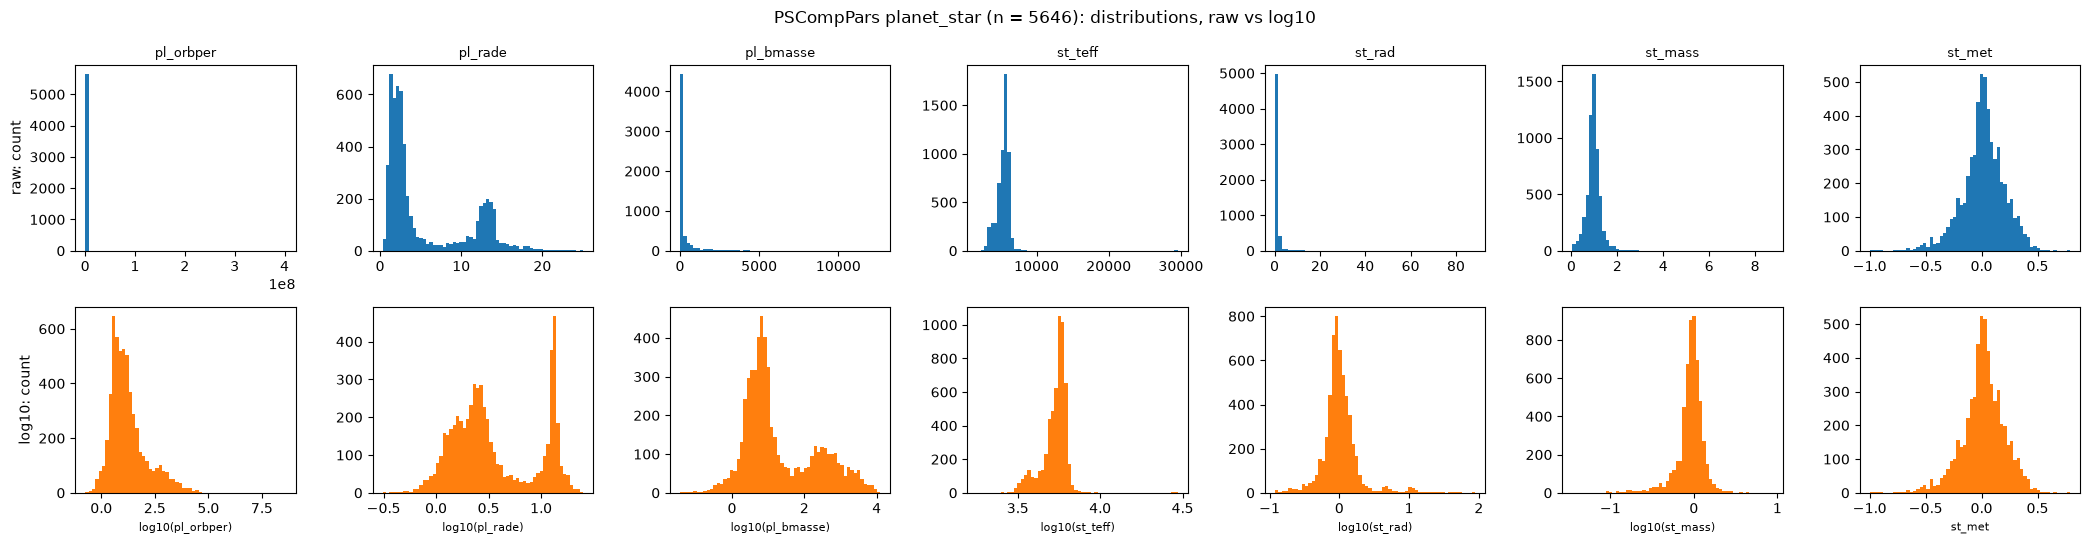

In [18]:
# Histograms, raw (top row) and log10 (bottom row), for all 7 features of planet_star
# (planet_basic uses the first 3 of them, on a slightly larger set of rows)
t, cols = tables["planet_star"], FEATURE_SETS["planet_star"]
L = log_view(t, cols)
fig, axes = plt.subplots(2, len(cols), figsize=(3 * len(cols), 5.5))
for j, c in enumerate(cols):
    axes[0, j].hist(t[c], bins=60)
    axes[0, j].set_title(c, fontsize=9)
    axes[1, j].hist(L[c], bins=60, color="tab:orange")
    axes[1, j].set_xlabel(c if c in NOT_LOGGED else f"log10({c})", fontsize=8)
axes[0, 0].set_ylabel("raw: count")
axes[1, 0].set_ylabel("log10: count")
fig.suptitle(f"PSCompPars planet_star (n = {len(t)}): distributions, raw vs log10")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_histograms_raw_log10.png", dpi=200)
plt.show()

### 3b. Correlations

Spearman depends only on ranks, so it is the same for raw and log10 values. Pearson is computed on both, because the
features span several orders of magnitude and Pearson is sensitive to that.

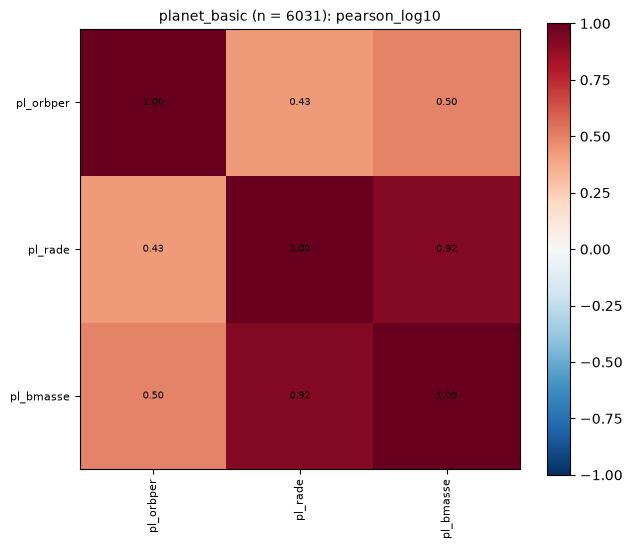

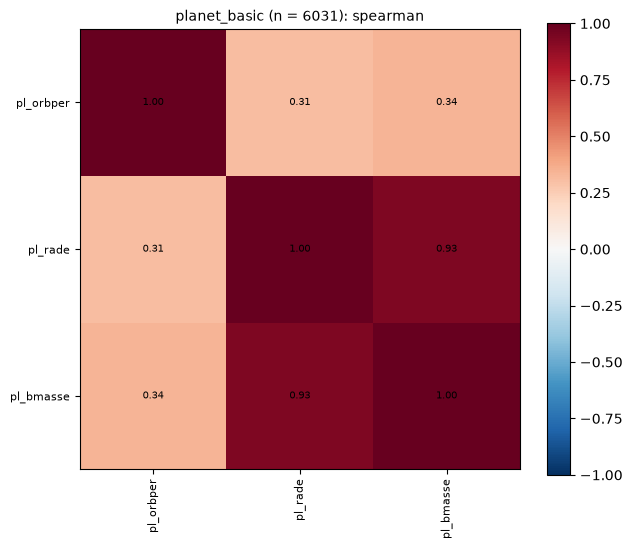

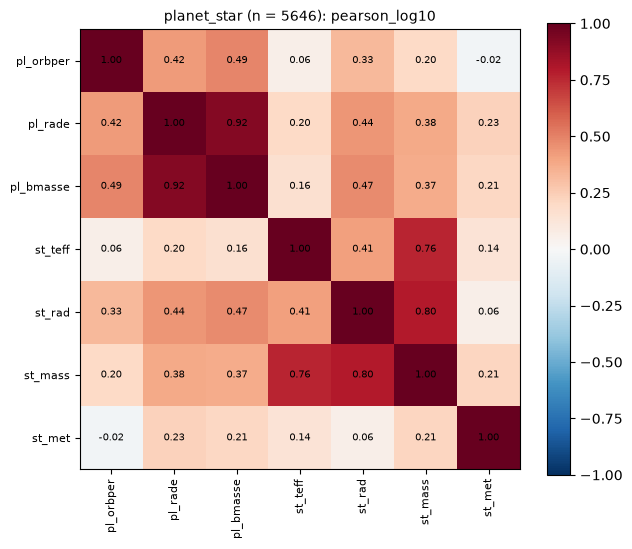

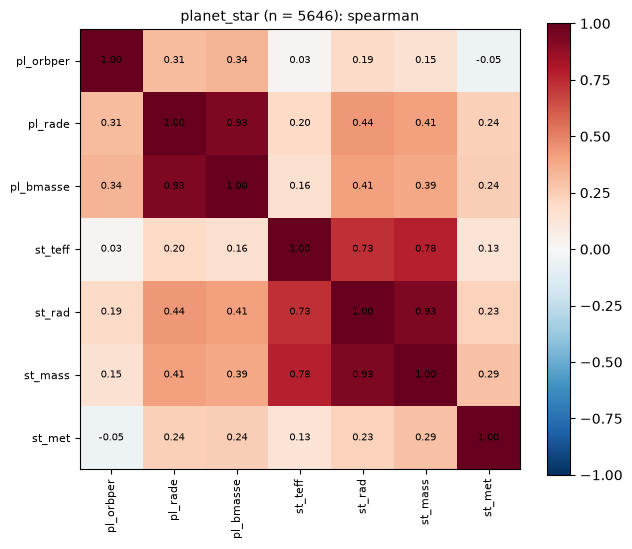

pearson_raw  pearson_log10  spearman           set
pl_rade   pl_bmasse        0.435          0.918     0.933  planet_basic
          pl_bmasse        0.434          0.918     0.931   planet_star
st_rad    st_mass          0.484          0.797     0.930   planet_star
st_teff   st_mass          0.431          0.760     0.775   planet_star
          st_rad          -0.064          0.409     0.728   planet_star
pl_rade   st_rad           0.221          0.444     0.435   planet_star
pl_bmasse st_rad           0.382          0.471     0.412   planet_star
pl_rade   st_mass          0.414          0.378     0.409   planet_star
pl_bmasse st_mass          0.336          0.373     0.390   planet_star
pl_orbper pl_bmasse        0.029          0.496     0.341  planet_basic
          pl_bmasse        0.029          0.486     0.341   planet_star
          pl_rade          0.018          0.424     0.313   planet_star
          pl_rade          0.020          0.427     0.312  planet_basic
st_mass   st_met           0.176          0.215     0.292   planet_star
pl_bmasse st_met           0.043          0.206     0.243   planet_star
pl_rade   st_met           0.200          0.230     0.239   planet_star
st_rad    st_met          -0.115          0.061     0.227   planet_star
pl_rade   st_teff          0.164          0.196     0.197   planet_star
pl_orbper st_rad          -0.004          0.325     0.194   planet_star
pl_bmasse st_teff          0.046          0.160     0.158   planet_star
pl_orbper st_mass         -0.022          0.198     0.154   planet_star
st_teff   st_met           0.099          0.138     0.134   planet_star
pl_orbper st_met          -0.001         -0.024    -0.053   planet_star
          st_teff         -0.023          0.055     0.029   planet_star

In [19]:
def corr_heatmap(corr, title, path):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax)
    ax.set_title(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()

all_pairs = []
for name, cols in FEATURE_SETS.items():
    t = tables[name]
    corrs = {
        "pearson_raw": t[cols].corr(method="pearson"),
        "pearson_log10": log_view(t, cols).corr(method="pearson"),
        "spearman": t[cols].corr(method="spearman"),
    }
    for kind, corr in corrs.items():
        corr.to_csv(OUT_DIR / f"pscomppars_{name}_corr_{kind}.csv")
    for kind in ("pearson_log10", "spearman"):
        corr_heatmap(corrs[kind], f"{name} (n = {len(t)}): {kind}", FIG_DIR / f"pscomppars_{name}_corr_{kind}.png")
    mask = np.triu(np.ones((len(cols), len(cols)), dtype=bool), k=1)
    pairs = pd.DataFrame({k: c.where(mask).stack().dropna() for k, c in corrs.items()})
    all_pairs.append(pairs.assign(set=name))

pairs = pd.concat(all_pairs).round(3)
pairs.to_csv(OUT_DIR / "pscomppars_correlation_pairs.csv")
pairs.sort_values("spearman", key=abs, ascending=False)

### 3c. Planets sharing the same host star

Two planets of the same system have identical values in the stellar columns, so in `planet_star` they differ only
in the planet columns. Counted by `hostname` inside each table (and compared with `sy_pnum`, the number of planets
the archive lists for the system).

In [20]:
share = {}
for name, t in tables.items():
    per_host = t["hostname"].value_counts()
    rows_in_multi = t["hostname"].map(per_host).gt(1)
    share[name] = {
        "rows": len(t),
        "distinct hosts": len(per_host),
        "hosts with >1 planet in table": int((per_host > 1).sum()),
        "rows whose host has >1 planet in table": int(rows_in_multi.sum()),
        "share of rows": round(rows_in_multi.mean(), 3),
        "max planets per host": int(per_host.max()),
    }
share = pd.DataFrame(share)
share.to_csv(OUT_DIR / "pscomppars_shared_hosts.csv")
print(share, "\n")

# planets per host in planet_star, and agreement with sy_pnum (planets may be missing from the table after filtering)
t = tables["planet_star"]
per_host = t["hostname"].value_counts()
print("planet_star: number of hosts by planets-per-host in the table")
print(per_host.value_counts().sort_index().rename("hosts"), "\n")
print("rows where planets of the host in the table < sy_pnum:", (t["hostname"].map(per_host) < t["sy_pnum"]).sum())

                                        planet_basic  planet_star
rows                                        6031.000     5646.000
distinct hosts                              4474.000     4148.000
hosts with >1 planet in table               1042.000     1002.000
rows whose host has >1 planet in table      2599.000     2500.000
share of rows                                  0.431        0.443
max planets per host                           8.000        8.000 

planet_star: number of hosts by planets-per-host in the table
count
1    3146
2     677
3     209
4      77
5      26
6      11
7       1
8       1
Name: hosts, dtype: int64 

rows where planets of the host in the table < sy_pnum: 57


In [21]:
# Is the stellar part really identical within a host? (it should be, PSCompPars has one set of stellar values per system)
star_cols = ["st_teff", "st_rad", "st_mass", "st_met"]
n_unique = t.groupby("hostname")[star_cols].nunique()
print("hosts with more than one distinct value, per stellar column:")
print((n_unique > 1).sum())

hosts with more than one distinct value, per stellar column:
st_teff    186
st_rad     188
st_mass    192
st_met     148
dtype: int64


### 3d. Recomputed density of the planet_basic rows

Density is not a feature, but ρ = 5.514 · M / R³ g/cm³ shows whether a mass–radius pair is physically odd.
Only the distribution and the most extreme rows are shown here; no cutoff is applied.

count     6031.000
mean        17.583
std        542.764
min          0.030
1%           0.171
5%           0.343
50%          2.590
95%         10.479
99%         55.109
max      39377.911
Name: dens_recomputed, dtype: float64 



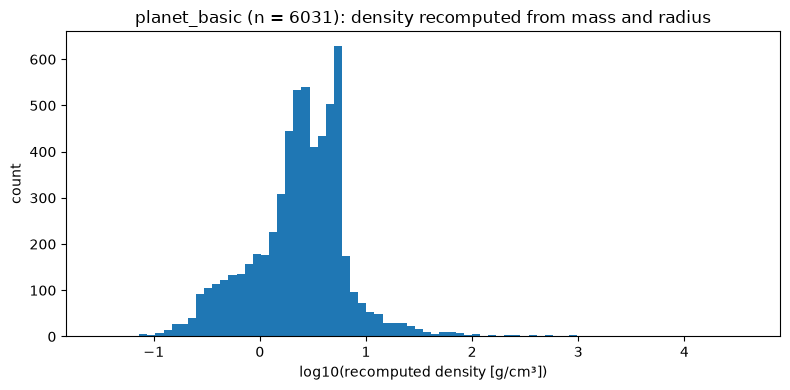

,pl_name,discoverymethod,pl_bmassprov,pl_bmasse,pl_rade,dens_recomputed
4423,Kepler-80 f,Transit,Mass,12651.50,1.21,39377.91
3657,Kepler-32 f,Transit,Mass,969.23,0.82,9692.84
3666,Kepler-324 b,Transit,Mass,2414.40,1.14,8985.90
1928,KOI-4777.01,Transit,Mass,99.20,0.51,4123.52
3410,Kepler-238 b,Transit,Mass,3305.02,1.73,3519.67
1424,K2-137 b,Transit,Mass,158.92,0.64,3342.66
3435,Kepler-245 e,Transit,Mass,1806.36,1.75,1858.48
1915,KOI-2513.01,Transit,Mass,7310.05,2.80,1831.76
3793,Kepler-37 e,Transit,Msini,8.10,0.37,881.75
4450,Kepler-82 d,Transit,Mass,885.10,1.77,880.11


In [22]:
t = tables["planet_basic"].copy()
t["dens_recomputed"] = 5.514 * t["pl_bmasse"] / t["pl_rade"] ** 3

print(t["dens_recomputed"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(3), "\n")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(t["dens_recomputed"]), bins=80)
ax.set_xlabel("log10(recomputed density [g/cm³])")
ax.set_ylabel("count")
ax.set_title(f"planet_basic (n = {len(t)}): density recomputed from mass and radius")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_density_recomputed.png", dpi=200)
plt.show()

top = t.nlargest(20, "dens_recomputed")[["pl_name", "discoverymethod", "pl_bmassprov", "pl_bmasse", "pl_rade", "dens_recomputed"]]
top.to_csv(OUT_DIR / "pscomppars_density_top20.csv", index=False)
top.round(2)

In [23]:
# The same distribution split by mass provenance (are odd mass-radius pairs specific to one provenance?)
print(t.groupby("pl_bmassprov")["dens_recomputed"].describe(percentiles=[0.05, 0.5, 0.95]).round(2))

                   count   mean     std   min    5%   50%    95%       max
pl_bmassprov                                                              
M-R relationship  3034.0   3.29    1.50  0.36  1.07  2.97   5.81      6.04
Mass              2090.0  44.40  921.35  0.03  0.22  2.04  27.70  39377.91
Msin(i)/sin(i)      15.0   2.84    2.78  0.43  0.53  1.73   6.77     11.06
Msini              892.0   3.62   29.61  0.23  0.30  1.56   8.58    881.75


## Step 4: Where do the values come from?

PSCompPars fills the gaps of each planet's default parameter set with values from other references or with
"calculations from published relations", so one row can mix sources (Christiansen et al. 2025, PSJ 6:186, Sec. 2.1.1).
Every value has a `*_reflink` column: an HTML link whose `refstr=` attribute names the reference
(e.g. `MORTON_ET_AL__2016`), or `CALCULATED_VALUE` when the archive computed it.

- **4a** which features are calculated values, per table
- **4b** how many rows take all their features from one single reference
- **4c** discovery facility of the rows in each table
- **4d** planets above the archive's inclusion limit of 30 Jupiter masses (Christiansen et al. 2025, Sec. 2.1.1)

In [24]:
def ref_id(col):
    """Reference identifier (the refstr attribute) of the *_reflink column of a feature."""
    return df[f"{col}_reflink"].str.extract(r"refstr=(\S+)", expand=False)

ALL_FEATURES = FEATURE_SETS["planet_star"]
refs = pd.DataFrame({c: ref_id(c) for c in ALL_FEATURES})
print("feature values without a parsable reference:")
print((refs.isna() & df[ALL_FEATURES].notna()).sum(), "\n")

# 4a. calculated values per feature, inside each table
calc = refs.eq("CALCULATED_VALUE")
calc_table = pd.DataFrame({
    name: calc.loc[df[cols].notna().all(axis=1), cols].sum().reindex(ALL_FEATURES)
    for name, cols in FEATURE_SETS.items()
})
calc_table.loc["rows with >=1 calculated feature"] = [
    calc.loc[df[cols].notna().all(axis=1), cols].any(axis=1).sum() for cols in FEATURE_SETS.values()]
calc_table.loc["rows in table"] = [len(t) for t in tables.values()]
calc_table.to_csv(OUT_DIR / "pscomppars_calculated_values.csv")
calc_table

feature values without a parsable reference:
pl_orbper    0
pl_rade      0
pl_bmasse    0
st_teff      0
st_rad       0
st_mass      0
st_met       0
dtype: int64 



,planet_basic,planet_star
pl_orbper,0.0,0
pl_rade,1218.0,1097
pl_bmasse,3034.0,2811
st_teff,NaN,0
st_rad,NaN,0
st_mass,NaN,0
st_met,NaN,0
rows with >=1 calculated feature,4252.0,3908
rows in table,6031.0,5646


In [25]:
# Calculated radius vs mass provenance (in the full table): are the calculated radii the same planets as the M-R masses?
pd.crosstab(df["pl_bmassprov"].fillna("(missing)"),
            np.where(df["pl_rade"].isna(), "radius missing",
                     np.where(calc["pl_rade"], "radius calculated", "radius from a reference")),
            margins=True)

col_0,radius calculated,radius from a reference,radius missing,All
pl_bmassprov,,,,
(missing),0,0,12,12
M-R relationship,0,3034,0,3034
Mass,655,1788,41,2484
Msin(i)/sin(i),13,2,0,15
Msini,875,41,9,925
All,1543,4865,62,6470


In [26]:
# The same crosstab by discovery method (which planets get a calculated radius?)
pd.crosstab(df["discoverymethod"],
            np.where(df["pl_rade"].isna(), "radius missing",
                     np.where(calc["pl_rade"], "radius calculated", "radius from a reference")),
            margins=True)

col_0,radius calculated,radius from a reference,radius missing,All
discoverymethod,,,,
Astrometry,8,0,0,8
Disk Kinematics,1,0,0,1
Eclipse Timing Variations,15,0,2,17
Imaging,53,41,4,98
Microlensing,294,0,0,294
Orbital Brightness Modulation,3,3,3,9
Pulsar Timing,6,0,2,8
Pulsation Timing Variations,2,0,0,2
Radial Velocity,1134,33,38,1205


### 4b. Rows whose features all come from one reference

Counted twice: requiring the same *published* reference for every feature (no calculated values), and for the
planet features only.

In [27]:
def single_source(cols):
    r = refs[cols]
    same = r.nunique(axis=1).eq(1) & r.notna().all(axis=1)
    return same & ~r.eq("CALCULATED_VALUE").any(axis=1)

PLANET_COLS = FEATURE_SETS["planet_basic"]
homog = {}
for name, cols in FEATURE_SETS.items():
    in_table = df[cols].notna().all(axis=1)
    homog[name] = {
        "rows in table": int(in_table.sum()),
        "all features from one reference": int((in_table & single_source(cols)).sum()),
        "planet features from one reference": int((in_table & single_source(PLANET_COLS)).sum()),
    }
homog = pd.DataFrame(homog)
homog.to_csv(OUT_DIR / "pscomppars_single_source_rows.csv")
homog

,planet_basic,planet_star
rows in table,6031,5646
all features from one reference,1559,1270
planet features from one reference,1559,1523


In [28]:
# planet_star rows with every feature from one reference: by discovery method and mass provenance,
# next to the whole planet_star table (does the restriction change the composition?)
in_star = df[FEATURE_SETS["planet_star"]].notna().all(axis=1)
one_ref = in_star & single_source(FEATURE_SETS["planet_star"])
for g in ("discoverymethod", "pl_bmassprov"):
    print(pd.DataFrame({"planet_star": df.loc[in_star, g].value_counts(),
                        "single reference": df.loc[one_ref, g].value_counts()}).fillna(0).astype(int), "\n")

# the references that contribute most of these single-source rows
print(refs.loc[one_ref, "pl_orbper"].value_counts().head(15))

                               planet_star  single reference
discoverymethod                                             
Astrometry                               6                 0
Eclipse Timing Variations                4                 0
Imaging                                 11                 0
Orbital Brightness Modulation            6                 1
Pulsation Timing Variations              1                 0
Radial Velocity                       1085                24
Transit                               4506              1244
Transit Timing Variations               27                 1 

                  planet_star  single reference
pl_bmassprov                                   
M-R relationship         2811                 0
Mass                     2007              1264
Msin(i)/sin(i)             12                 2
Msini                     816                 4 

pl_orbper
STASSUN_ET_AL__2017         77
BONOMO_ET_AL_2023           39
YEE_ET_AL_2025            

### 4c. Discovery facility

In [29]:
fac = pd.DataFrame({name: df.loc[df[cols].notna().all(axis=1), "disc_facility"].value_counts()
                    for name, cols in FEATURE_SETS.items()}).fillna(0).astype(int)
fac.insert(0, "all planets", df["disc_facility"].value_counts())
fac = fac.fillna(0).astype(int).sort_values("all planets", ascending=False)
fac.to_csv(OUT_DIR / "pscomppars_discovery_facility.csv", index_label="disc_facility")
fac.head(15)

,all planets,planet_basic,planet_star
disc_facility,,,
Kepler,2787,2764,2761
Transiting Exoplanet Survey Satellite (TESS),1023,1018,830
K2,549,546,499
Multiple Observatories,354,339,289
La Silla Observatory,311,291,278
W. M. Keck Observatory,194,177,174
SuperWASP,121,119,117
OGLE,112,15,8
HATSouth,73,73,69


### 4d. Planets above 30 Jupiter masses

`pl_bmassj` is the same mass in Jupiter masses. The archive's criterion is mass (or minimum mass) ≤ 30 M_J.

In [30]:
over = df["pl_bmassj"] > 30
print("planets above 30 M_J in the full table:", over.sum())
for name, cols in FEATURE_SETS.items():
    print(f"  in {name}:", (over & df[cols].notna().all(axis=1)).sum())
df.loc[over, ["pl_name", "discoverymethod", "pl_bmassprov", "pl_bmassj", "pl_bmasse", "pl_rade"]] \
  .assign(mass_ref=ref_id("pl_bmasse")[over]).sort_values("pl_bmassj", ascending=False)

planets above 30 M_J in the full table: 1
  in planet_basic: 1
  in planet_star: 1


,pl_name,discoverymethod,pl_bmassprov,pl_bmassj,pl_bmasse,pl_rade,mass_ref
4676,Kepler-80 f,Transit,Mass,39.806071,12651.5,1.21,OFIR_ET_AL__2025


## Step 5: Uncertainties and limit flags

The notebook reads the full download (17 Nov 2026, with uncertainties and limits). Compared with the first
values-only download (16 Nov 2026), it adds for each parameter `<col>err1` (upper uncertainty), `<col>err2` (lower uncertainty, negative) and
`<col>lim` (limit flag). The archive documentation describes the limit flag as 0 = measured value, 1 = upper limit,
−1 = lower limit (to be checked against the column documentation on the archive website).

- **5a** is the full file the same table as the first, values-only one (same planets, same values)?
- **5b** limit flags of period, radius and mass
- **5c** relative uncertainties, and the odd mass–radius pairs seen in Step 3d

In [31]:
CSV_FIRST_PATH = DATA_DIR / "PSCompPars_2026.11.16_01.03.51.csv"     # first download, values only
df_first = pd.read_csv(CSV_FIRST_PATH, comment="#", low_memory=False)
dfu = df                                                                 # the full file read in Step 1
print("full file:", dfu.shape, "  first file:", df_first.shape)
print("columns of the first file missing in the full one:", [c for c in df_first.columns if c not in dfu.columns])
print("new columns:", dfu.shape[1] - len([c for c in df_first.columns if c in dfu.columns]))

# 5a. same planets?
old_names, new_names = set(df_first["pl_name"]), set(dfu["pl_name"])
print("planets only in the first file:", sorted(old_names - new_names))
print("planets only in the full file: ", sorted(new_names - old_names))

# same values for the columns used so far?
CHECK = ALL_FEATURES + [f"{c}_reflink" for c in ALL_FEATURES] + ["pl_bmassprov", "discoverymethod", "hostname"]
a = df_first.set_index("pl_name").loc[sorted(old_names & new_names), CHECK]
b = dfu.set_index("pl_name").loc[sorted(old_names & new_names), CHECK]
differs = ~((a == b) | (a.isna() & b.isna()))
print("\nplanets in both files:", len(a))
print("values that differ between the files, per column:")
print(differs.sum()[differs.sum() > 0] if differs.values.any() else "none")

full file: (6470, 325)   first file: (6470, 174)
columns of the first file missing in the full one: []
new columns: 151
planets only in the first file: []
planets only in the full file:  []

planets in both files: 6470
values that differ between the files, per column:
none


In [32]:
# rows whose values changed (if any), side by side
changed = differs.any(axis=1)
if changed.any():
    cols = differs.columns[differs.any()]
    display(pd.concat({"first": a.loc[changed, cols], "new": b.loc[changed, cols]}, axis=1))

### 5b. Limit flags

In [33]:
LIM_COLS = {c: f"{c}lim" for c in ["pl_orbper", "pl_rade", "pl_bmasse"]}
print("limit flag counts (all planets, NaN = no value):")
print(pd.DataFrame({c: dfu[l].value_counts(dropna=False) for c, l in LIM_COLS.items()}).fillna(0).astype(int), "\n")

print("mass limit flag by mass provenance:")
print(pd.crosstab(dfu["pl_bmassprov"].fillna("(missing)"), dfu["pl_bmasselim"].astype(object).fillna("NaN"), margins=True))

limit flag counts (all planets, NaN = no value):
      pl_orbper  pl_rade  pl_bmasse
-1.0          6        5         13
 0.0       6102     6403       6189
 1.0          0        0        225
 NaN        362       62         43 

mass limit flag by mass provenance:
pl_bmasselim      -1.0   0.0   1.0   NaN   All
pl_bmassprov                                  
(missing)            0     0     0    12    12
M-R relationship     0  3034     0     0  3034
Mass                11  2249   224     0  2484
Msin(i)/sin(i)       0    15     0     0    15
Msini                2   891     1    31   925
All                 13  6189   225    43  6470


In [34]:
# Rows with a non-zero limit flag in period, radius or mass, among the planet_basic rows
in_basic_u = dfu[FEATURE_SETS["planet_basic"]].notna().all(axis=1)
any_lim = dfu[list(LIM_COLS.values())].fillna(0).ne(0).any(axis=1)
print("planet_basic rows with a non-zero limit flag:", (in_basic_u & any_lim).sum(), "of", in_basic_u.sum())
lim_rows = dfu.loc[in_basic_u & any_lim, ["pl_name", "discoverymethod", "pl_bmassprov"]
                   + [x for c, l in LIM_COLS.items() for x in (c, l)]]
lim_rows.to_csv(OUT_DIR / "pscomppars_limit_flag_rows.csv", index=False)
lim_rows

planet_basic rows with a non-zero limit flag: 199 of 6031


,pl_name,discoverymethod,pl_bmassprov,pl_orbper,pl_orbperlim,pl_rade,pl_radelim,pl_bmasse,pl_bmasselim
119,CoRoT-24 b,Transit,Mass,5.113400,0.0,3.700000,0.0,5.700000,1.0
131,CoRoT-36 b,Transit,Mass,5.616531,0.0,15.804663,0.0,216.123317,1.0
158,DS Tuc A b,Transit,Mass,8.138268,0.0,5.700000,0.0,413.179000,1.0
198,EPIC 248847494 b,Transit,Mass,3650.000000,0.0,12.441990,0.0,4131.790000,1.0
271,GJ 341 b,Transit,Mass,7.576860,0.0,0.880000,0.0,4.000000,1.0
...,...,...,...,...,...,...,...,...,...
6157,TOI-942 b,Transit,Mass,4.324210,0.0,3.890000,0.0,826.358000,1.0
6158,TOI-942 c,Transit,Mass,10.156272,0.0,4.670000,0.0,37.000000,1.0
6271,WASP-167 b,Transit,Mass,2.021960,0.0,17.710220,0.0,2542.640000,1.0
6418,XO-6 b,Transit,Mass,3.765001,0.0,23.202630,0.0,1398.452000,1.0


### 5c. Relative uncertainties

Relative uncertainty = mean of the upper and lower uncertainty divided by the value:
(err1 − err2) / 2 / value (err2 is stored as a negative number).

In [35]:
def rel_unc(col):
    return (dfu[f"{col}err1"] - dfu[f"{col}err2"]) / 2 / dfu[col]

ru = pd.DataFrame({c: rel_unc(c) for c in LIM_COLS})
print("relative uncertainty, planet_basic rows (count = rows that have uncertainties):")
print(ru[in_basic_u].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3), "\n")

print("relative mass uncertainty by mass provenance (planet_basic rows):")
print(ru.loc[in_basic_u, "pl_bmasse"].groupby(dfu.loc[in_basic_u, "pl_bmassprov"])
        .describe(percentiles=[0.5, 0.95]).round(3))

relative uncertainty, planet_basic rows (count = rows that have uncertainties):
       pl_orbper   pl_rade  pl_bmasse
count   5538.000  4432.000   2766.000
mean       0.008     0.132      0.183
std        0.052     0.616      0.246
min        0.000     0.000      0.000
5%         0.000     0.020      0.031
25%        0.000     0.044      0.072
50%        0.000     0.078      0.125
75%        0.000     0.150      0.213
95%        0.017     0.432      0.533
99%        0.266     0.538      0.971
max        0.902    38.798      6.225 

relative mass uncertainty by mass provenance (planet_basic rows):
                   count   mean    std    min    50%    95%    max
pl_bmassprov                                                      
M-R relationship     0.0    NaN    NaN    NaN    NaN    NaN    NaN
Mass              1888.0  0.203  0.249  0.000  0.136  0.579  6.225
Msin(i)/sin(i)      15.0  0.192  0.266  0.032  0.102  0.713  1.009
Msini              863.0  0.140  0.231  0.000  0.101  0.322  

In [36]:
# The 20 highest recomputed densities (Step 3d) with their limit flags and relative uncertainties
dens_u = 5.514 * dfu["pl_bmasse"] / dfu["pl_rade"] ** 3
top_idx = dens_u[in_basic_u].nlargest(20).index
top_u = dfu.loc[top_idx, ["pl_name", "pl_bmassprov", "pl_bmasse", "pl_bmasselim", "pl_rade", "pl_radelim"]].assign(
    dens_recomputed=dens_u[top_idx].round(1),
    rel_unc_mass=ru.loc[top_idx, "pl_bmasse"].round(2),
    rel_unc_radius=ru.loc[top_idx, "pl_rade"].round(2),
    mass_ref=dfu.loc[top_idx, "pl_bmasse_reflink"].str.extract(r"refstr=(\S+)", expand=False),
)
top_u.to_csv(OUT_DIR / "pscomppars_density_top20_uncertainty.csv", index=False)
top_u

,pl_name,pl_bmassprov,pl_bmasse,pl_bmasselim,pl_rade,pl_radelim,dens_recomputed,rel_unc_mass,rel_unc_radius,mass_ref
4676,Kepler-80 f,Mass,12651.500000,1.0,1.210000,0.0,39377.9,NaN,0.05,OFIR_ET_AL__2025
3895,Kepler-32 f,Mass,969.228000,1.0,0.820000,0.0,9692.8,NaN,0.09,OFIR_ET_AL__2025
3904,Kepler-324 b,Mass,2414.400000,1.0,1.140000,0.0,8985.9,NaN,0.10,OFIR_ET_AL__2025
2159,KOI-4777.01,Mass,99.200000,1.0,0.510000,0.0,4123.5,NaN,0.06,CA_NTILDE_AS_ET_AL__2022
3647,Kepler-238 b,Mass,3305.020000,1.0,1.730000,0.0,3519.7,NaN,0.23,OFIR_ET_AL__2025
1506,K2-137 b,Mass,158.915000,1.0,0.640000,0.0,3342.7,NaN,0.16,SMITH_ET_AL__2018
3672,Kepler-245 e,Mass,1806.360000,1.0,1.750000,0.0,1858.5,NaN,0.04,OFIR_ET_AL__2025
2146,KOI-2513.01,Mass,7310.053361,0.0,2.802245,0.0,1831.8,0.09,4.10,CA_NTILDE_AS_ET_AL__2023
4031,Kepler-37 e,Msini,8.100000,0.0,0.370000,0.0,881.8,0.21,0.49,WEISS_ET_AL__2024
4703,Kepler-82 d,Mass,885.098000,1.0,1.770000,0.0,880.1,NaN,0.15,OFIR_ET_AL__2025


## Step 6: The "measured" table (main analysis)

Decision (Steps 4-5): the main analysis uses only planets whose period, radius and mass are **measured values**:

1. period, radius and mass present (the `planet_basic` rows)
2. mass provenance = `Mass` (not calculated from the radius by the archive, not a minimum mass M·sin i)
3. radius taken from a reference (not `CALCULATED_VALUE`)
4. limit flag = 0 for period, radius and mass (no upper or lower limits)

The whole `planet_basic` table is kept as the comparison. `measured_star` adds the four stellar features
(never calculated, Step 4a). Uncertainties are shown but not used to filter.

In [37]:
conditions = {
    "1. period, radius, mass present": df[FEATURE_SETS["planet_basic"]].notna().all(axis=1),
    "2. mass provenance = Mass": df["pl_bmassprov"].eq("Mass"),
    "3. radius from a reference": ~ref_id("pl_rade").eq("CALCULATED_VALUE"),
    "4. no limit flags": df[list(LIM_COLS.values())].eq(0).all(axis=1),
}
keep = pd.Series(True, index=df.index)
funnel = {}
for label, cond in conditions.items():
    keep &= cond
    funnel[label] = int(keep.sum())
measured_mask = keep.copy()
measured_star_mask = measured_mask & df[FEATURE_SETS["planet_star"]].notna().all(axis=1)
funnel["5. + stellar features present (measured_star)"] = int(measured_star_mask.sum())
funnel = pd.Series(funnel, name="rows kept")
funnel.to_csv(OUT_DIR / "pscomppars_measured_funnel.csv")
print(funnel, "\n")
print("Kepler-80 f kept:", bool(measured_mask[df["pl_name"].eq("Kepler-80 f")].any()))

UNC_COLS = [f"{c}err{k}" for c in LIM_COLS for k in (1, 2)]
tables["measured"] = df.loc[measured_mask, INFO_COLS + FEATURE_SETS["planet_basic"] + UNC_COLS].reset_index(drop=True)
tables["measured_star"] = df.loc[measured_star_mask, INFO_COLS + FEATURE_SETS["planet_star"] + UNC_COLS].reset_index(drop=True)
FEATURE_SETS["measured"] = FEATURE_SETS["planet_basic"]
FEATURE_SETS["measured_star"] = FEATURE_SETS["planet_star"]
for name in ("measured", "measured_star"):
    tables[name].to_csv(OUT_DIR / f"pscomppars_{name}.csv", index=False)
    print(f"{name}: {len(tables[name])} rows -> pscomppars_{name}.csv")

1. period, radius, mass present                  6031
2. mass provenance = Mass                        2090
3. radius from a reference                       1760
4. no limit flags                                1564
5. + stellar features present (measured_star)    1530
Name: rows kept, dtype: int64 

Kepler-80 f kept: False
measured: 1564 rows -> pscomppars_measured.csv
measured_star: 1530 rows -> pscomppars_measured_star.csv


### 6a. Composition compared with planet_basic

In [38]:
for g in ("discoverymethod", "disc_facility"):
    comp = pd.DataFrame({
        "planet_basic": df.loc[conditions["1. period, radius, mass present"], g].value_counts(),
        "measured": df.loc[measured_mask, g].value_counts(),
        "measured_star": df.loc[measured_star_mask, g].value_counts(),
    }).fillna(0).astype(int).sort_values("planet_basic", ascending=False)
    comp.to_csv(OUT_DIR / f"pscomppars_measured_by_{g}.csv", index_label=g)
    print(comp.head(12), "\n")

per_host = tables["measured"]["hostname"].value_counts()
print("measured: distinct hosts", len(per_host), "| rows whose host has >1 planet in the table:",
      int(tables["measured"]["hostname"].map(per_host).gt(1).sum()))

                               planet_basic  measured  measured_star
discoverymethod                                                     
Transit                                4764      1520           1491
Radial Velocity                        1167        26             26
Transit Timing Variations                27         2              2
Imaging                                  25        13              8
Eclipse Timing Variations                15         0              0
Microlensing                             12         0              0
Astrometry                                8         0              0
Orbital Brightness Modulation             6         3              3
Pulsar Timing                             5         0              0
Pulsation Timing Variations               2         0              0 

                                              planet_basic  measured  \
disc_facility                                                          
Kepler                    

In [39]:
# Relative uncertainties inside the measured table (shown, not used to filter)
print(ru.loc[measured_mask].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(3))

       pl_orbper   pl_rade  pl_bmasse
count   1461.000  1552.000   1554.000
mean       0.002     0.067      0.206
std        0.029     0.128      0.265
min        0.000     0.003      0.000
5%         0.000     0.014      0.036
50%        0.000     0.041      0.136
95%        0.000     0.195      0.588
99%        0.002     0.473      1.021
max        0.709     4.100      6.225


### 6b. Distributions and the mass–radius relation

Where do the measured planets sit in the mass–radius plane, compared with the planets whose mass or radius
was calculated by the archive?

mass calculated from radius    3034
measured (main table)          1564
radius calculated from mass    1218
other (Msini, limits, ...)      215
Name: count, dtype: int64 



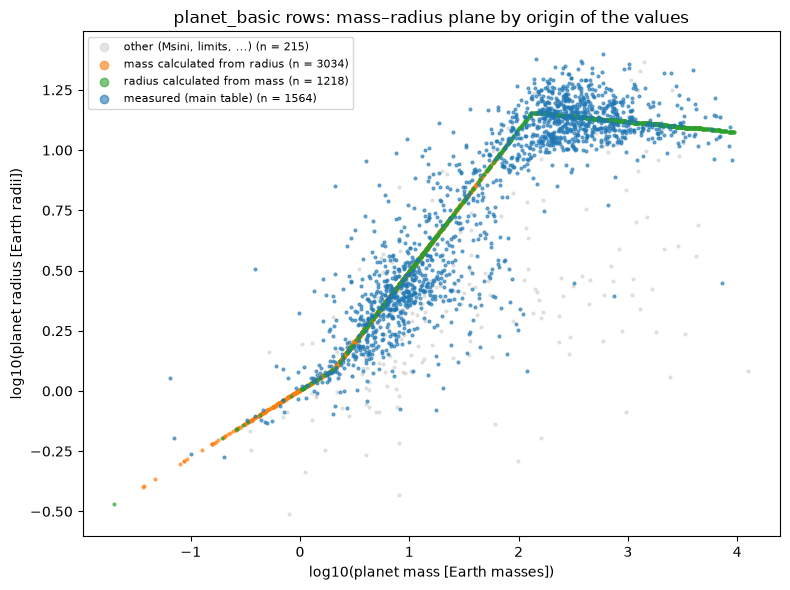

In [40]:
basic = conditions["1. period, radius, mass present"]
calc_mass = ref_id("pl_bmasse").eq("CALCULATED_VALUE")
calc_rad = ref_id("pl_rade").eq("CALCULATED_VALUE")
group = pd.Series("other (Msini, limits, ...)", index=df.index)
group[calc_mass] = "mass calculated from radius"
group[calc_rad] = "radius calculated from mass"
group[measured_mask] = "measured (main table)"
print(group[basic].value_counts(), "\n")

fig, ax = plt.subplots(figsize=(8, 6))
for g, color in [("other (Msini, limits, ...)", "lightgrey"), ("mass calculated from radius", "tab:orange"),
                 ("radius calculated from mass", "tab:green"), ("measured (main table)", "tab:blue")]:
    sel = basic & group.eq(g)
    ax.scatter(np.log10(df.loc[sel, "pl_bmasse"]), np.log10(df.loc[sel, "pl_rade"]), s=4, alpha=0.6,
               color=color, label=f"{g} (n = {sel.sum()})")
ax.set_xlabel("log10(planet mass [Earth masses])")
ax.set_ylabel("log10(planet radius [Earth radii])")
ax.set_title("planet_basic rows: mass–radius plane by origin of the values")
ax.legend(fontsize=8, markerscale=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_mass_radius_by_origin.png", dpi=200)
plt.show()

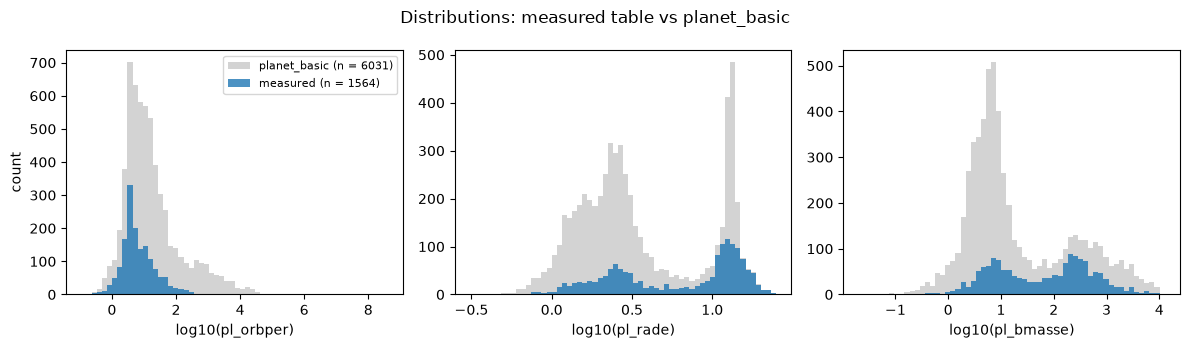

           skew_log10 planet_basic  skew_log10 measured
pl_orbper                    1.399                3.195
pl_rade                      0.350               -0.423
pl_bmasse                    0.751               -0.079


In [41]:
# log10 histograms: measured vs planet_basic
cols = FEATURE_SETS["planet_basic"]
fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.5))
for ax, c in zip(axes, cols):
    bins = np.histogram_bin_edges(np.log10(df.loc[basic, c]), bins=60)
    ax.hist(np.log10(df.loc[basic, c]), bins=bins, color="lightgrey", label=f"planet_basic (n = {basic.sum()})")
    ax.hist(np.log10(df.loc[measured_mask, c]), bins=bins, color="tab:blue", alpha=0.8,
            label=f"measured (n = {measured_mask.sum()})")
    ax.set_xlabel(f"log10({c})")
axes[0].set_ylabel("count")
axes[0].legend(fontsize=8)
fig.suptitle("Distributions: measured table vs planet_basic")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_measured_vs_basic_hist.png", dpi=200)
plt.show()

print(pd.DataFrame({
    "skew_log10 planet_basic": np.log10(tables["planet_basic"][cols]).skew(),
    "skew_log10 measured": np.log10(tables["measured"][cols]).skew(),
}).round(3))

                     pearson_log10  spearman          table     n
pl_orbper pl_bmasse          0.496     0.341   planet_basic  6031
          pl_bmasse         -0.008    -0.203       measured  1564
          pl_bmasse          0.486     0.341    planet_star  5646
          pl_bmasse         -0.040    -0.203  measured_star  1530
          pl_rade            0.427     0.312   planet_basic  6031
          pl_rade           -0.035    -0.252       measured  1564
          pl_rade            0.424     0.313    planet_star  5646
          pl_rade           -0.055    -0.253  measured_star  1530
pl_rade   pl_bmasse          0.918     0.933   planet_basic  6031
          pl_bmasse          0.879     0.842       measured  1564
          pl_bmasse          0.918     0.931    planet_star  5646
          pl_bmasse          0.880     0.845  measured_star  1530


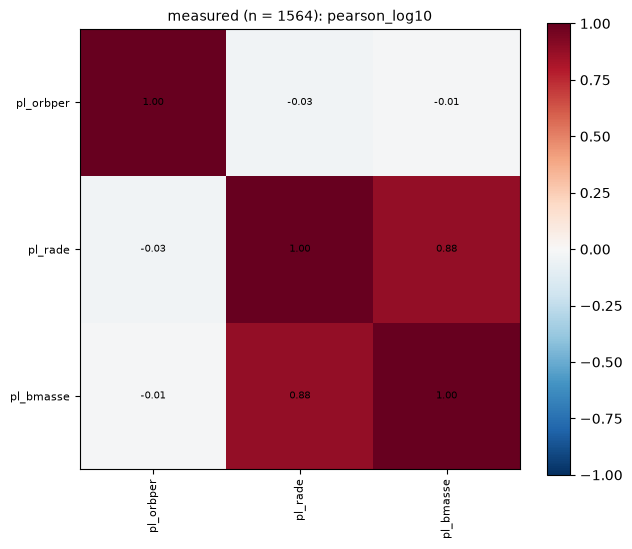

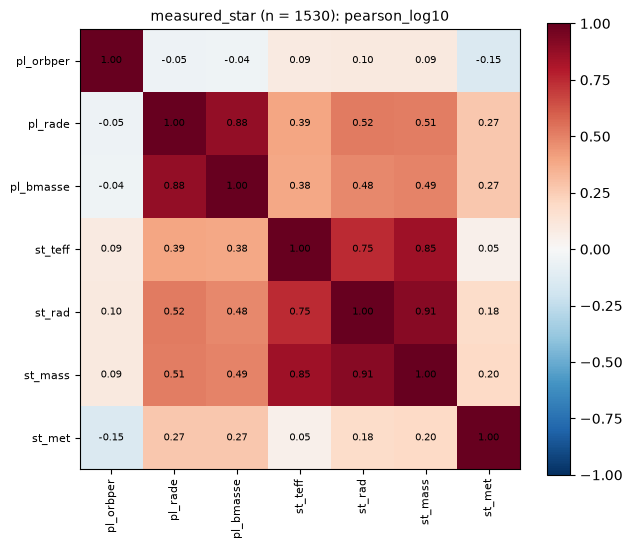

In [42]:
# Correlations: measured vs planet_basic (and the stellar versions)
rows = []
for name in ("planet_basic", "measured", "planet_star", "measured_star"):
    t, cols = tables[name], FEATURE_SETS[name]
    L = log_view(t, cols)
    mask = np.triu(np.ones((len(cols), len(cols)), dtype=bool), k=1)
    pr = L.corr(method="pearson").where(mask).stack().dropna().rename("pearson_log10")
    sp = t[cols].corr(method="spearman").where(mask).stack().dropna().rename("spearman")
    rows.append(pd.concat([pr, sp], axis=1).assign(table=name, n=len(t)))
corr_cmp = pd.concat(rows).round(3)
corr_cmp.to_csv(OUT_DIR / "pscomppars_measured_correlation_pairs.csv")
print(corr_cmp.loc[[("pl_rade", "pl_bmasse"), ("pl_orbper", "pl_rade"), ("pl_orbper", "pl_bmasse")]]
      .sort_index(level=[0, 1]).to_string())

for name in ("measured", "measured_star"):
    cols = FEATURE_SETS[name]
    corr_heatmap(log_view(tables[name], cols).corr(method="pearson"),
                 f"{name} (n = {len(tables[name])}): pearson_log10", FIG_DIR / f"pscomppars_{name}_corr_pearson_log10.png")

In [43]:
# Recomputed density inside the measured table
t = tables["measured"]
dens_m = 5.514 * t["pl_bmasse"] / t["pl_rade"] ** 3
print(dens_m.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(3), "\n")
t.assign(dens_recomputed=dens_m.round(2)).nlargest(10, "dens_recomputed")[
    ["pl_name", "discoverymethod", "pl_bmasse", "pl_bmasseerr1", "pl_bmasseerr2", "pl_rade", "pl_radeerr1", "dens_recomputed"]]

count    1564.000
mean        5.400
std        48.605
min         0.030
1%          0.102
5%          0.196
50%         1.480
95%        11.964
99%        56.537
max      1831.761
dtype: float64 



,pl_name,discoverymethod,pl_bmasse,pl_bmasseerr1,pl_bmasseerr2,pl_rade,pl_radeerr1,dens_recomputed
432,KOI-2513.01,Transit,7310.053361,635.656814,-635.656814,2.802245,22.417961,1831.76
646,Kepler-415 b,Transit,119.900000,102.100000,-87.400000,1.210000,0.130000,373.19
524,Kepler-203 c,Transit,749.900000,419.100000,-344.700000,2.470000,0.470000,274.40
669,Kepler-450 d,Transit,17.600000,9.500000,-6.700000,0.837000,0.068000,165.50
559,Kepler-272 b,Transit,78.000000,93.800000,-66.900000,1.430000,0.770000,147.08
601,Kepler-327 c,Transit,20.300000,27.100000,-17.700000,1.030000,0.050000,102.44
560,Kepler-272 c,Transit,97.800000,55.500000,-33.900000,1.790000,0.960000,94.03
572,Kepler-281 b,Transit,324.000000,82.000000,-65.000000,2.820000,1.120000,79.66
480,Kepler-131 c,Transit,8.250000,5.900000,-5.900000,0.840000,0.070000,76.75
616,Kepler-349 b,Transit,94.500000,70.800000,-60.300000,1.900000,0.720000,75.97


## Step 7: Preprocessing variants

Decision: all 1,564 rows of `measured` are kept (no filter on uncertainties); special cases (Imaging planets,
KOI-2513.01, very uncertain masses) are looked at after clustering.

Tables clustered: **measured** (main, 3 features), **measured_star** (7 features), and **planet_basic**
(comparison: includes the archive's calculated values).

Every feature except `st_met` spans orders of magnitude (Step 3a), so all variants start from log10
(`st_met` is already logarithmic and is used as it is):

- **log10_zscore**: log10, then (x − mean) / std (population std)
- **log10_minmax**: log10, then (x − min) / (max − min)

A z-score on the raw values is not used: with skewness up to 75 (period) the distances would be dominated by a few
extreme rows. The discovery method and the other info columns are kept aside, they are not used by the clustering.

In [44]:
def zscore(A):
    return (A - A.mean(axis=0)) / A.std(axis=0)

def minmax(A):
    return (A - A.min(axis=0)) / (A.max(axis=0) - A.min(axis=0))

CLUSTER_TABLES = ["measured", "measured_star", "planet_basic"]
VARIANTS = {"log10_zscore": zscore, "log10_minmax": minmax}

data = {}                                   # (table, variant) -> numpy array n x p
for tname in CLUSTER_TABLES:
    cols = FEATURE_SETS[tname]
    L = log_view(tables[tname], cols).to_numpy(dtype=float)
    assert np.isfinite(L).all(), tname
    for vname, f in VARIANTS.items():
        A = f(L)
        data[(tname, vname)] = A
        out = pd.DataFrame(A, columns=cols)
        out.insert(0, "pl_name", tables[tname]["pl_name"].values)
        out.to_csv(OUT_DIR / f"pscomppars_{tname}_{vname}.csv", index=False)
        print(f"{tname:14s} {vname:13s} shape={A.shape}  value range=[{A.min():.3f}, {A.max():.3f}]")

measured       log10_zscore  shape=(1564, 3)  value range=[-3.196, 11.526]
measured       log10_minmax  shape=(1564, 3)  value range=[0.000, 1.000]
measured_star  log10_zscore  shape=(1530, 7)  value range=[-5.980, 12.472]
measured_star  log10_minmax  shape=(1530, 7)  value range=[0.000, 1.000]
planet_basic   log10_zscore  shape=(6031, 3)  value range=[-2.981, 8.102]
planet_basic   log10_minmax  shape=(6031, 3)  value range=[0.000, 1.000]


In [45]:
# Share of each feature in the total variance (= its average share in the squared distances).
# Equal (1/p) under z-score by construction; under min-max it depends on each feature's distribution.
shares = {}
for tname in CLUSTER_TABLES:
    A = data[(tname, "log10_minmax")]
    shares[tname] = pd.Series(A.var(axis=0) / A.var(axis=0).sum(), index=FEATURE_SETS[tname])
shares = pd.DataFrame(shares).round(3)
shares.to_csv(OUT_DIR / "pscomppars_minmax_variance_share.csv")
shares

,measured,measured_star,planet_basic
pl_bmasse,0.346,0.223,0.366
pl_orbper,0.053,0.032,0.109
pl_rade,0.601,0.392,0.524
st_mass,NaN,0.091,NaN
st_met,NaN,0.116,NaN
st_rad,NaN,0.101,NaN
st_teff,NaN,0.045,NaN


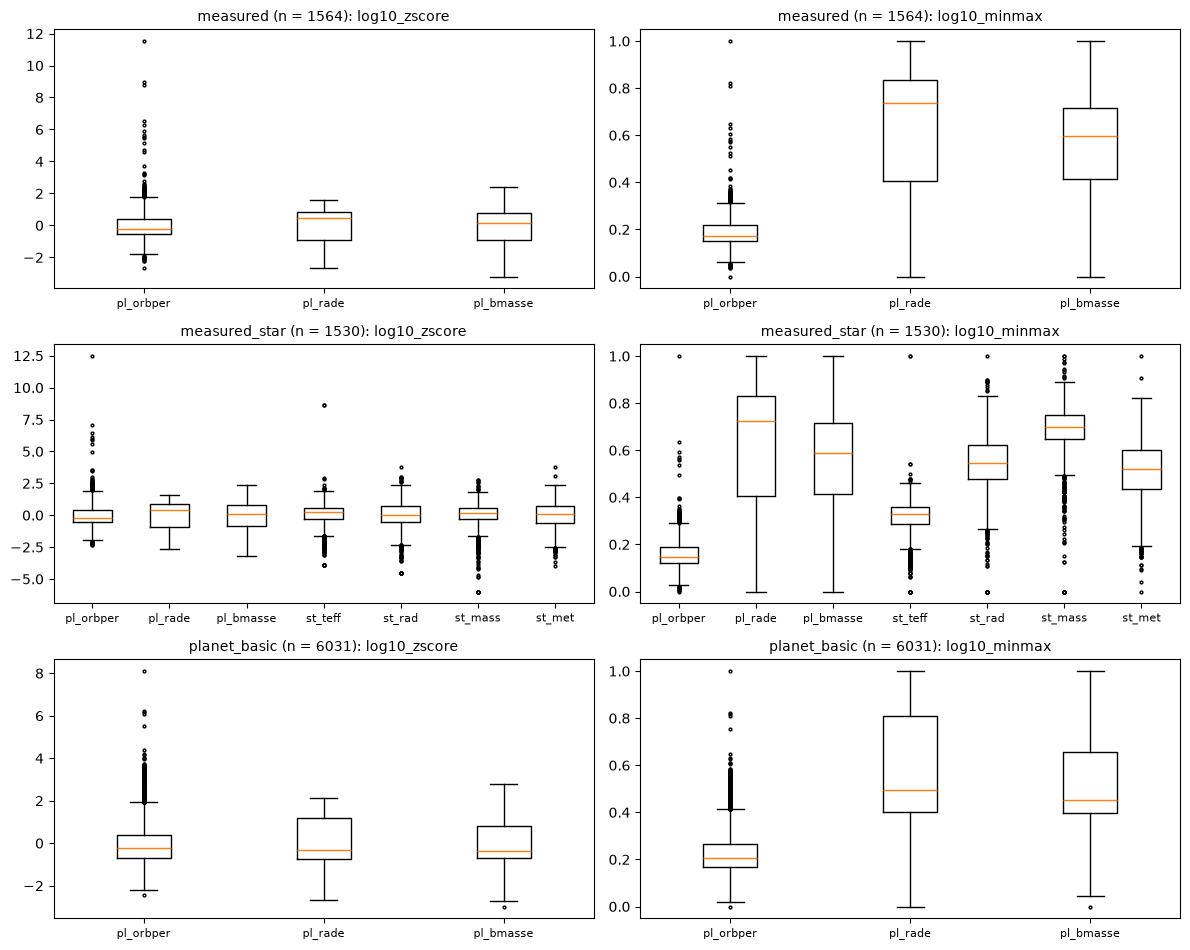

In [46]:
fig, axes = plt.subplots(len(CLUSTER_TABLES), 2, figsize=(12, 3.2 * len(CLUSTER_TABLES)))
for i, tname in enumerate(CLUSTER_TABLES):
    for j, vname in enumerate(VARIANTS):
        ax = axes[i, j]
        ax.boxplot(data[(tname, vname)], whis=1.5, flierprops={"markersize": 2})
        ax.set_xticks(range(1, len(FEATURE_SETS[tname]) + 1), FEATURE_SETS[tname], fontsize=8)
        ax.set_title(f"{tname} (n = {len(tables[tname])}): {vname}", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_scaling_comparison.png", dpi=200)
plt.show()

## Step 8: Number of clusters c and fuzzifier m

Same procedure as for WDBC: FCM from `src/fcm.py` (cross-checked there against scikit-fuzzy), for every table and
preprocessing variant, c = 2 ... 10 and m in `M_GRID`, `N_INIT` = 10 random starts (seeds `SEED`, `SEED + 1`, ...),
the run with the lowest J is kept. `M_GRID` also contains the dimension-dependent fuzzifier of Winkler et al. (2011),
m = (2 + p) / p: 1.667 for p = 3 and 1.286 for p = 7.

There are no class labels here, so this step uses only the internal validity indices
(PC, NPC, PE, NPE, XB, FS; lecture 05a, slides 76-82) and the prototype diagnostics (are the c prototypes distinct?).
For each m, compare the indices **across c**, not across m. About 3,800 FCM runs; this may take several minutes
(planet_basic has 6,031 rows).

In [47]:
import sys, time
sys.path.insert(0, "..")          # make src/ importable (this notebook is in src/nasa/)
import importlib
import fcm
importlib.reload(fcm)

SEED = 42
FCM_EPS, FCM_MAX_ITER = 1e-5, 1000
C_RANGE = range(2, 11)
N_INIT = 10
M_BASE = [1.1, 1.25, 1.5, 1.75, 2.0, 2.5]
INDICES = {"PC": "max", "NPC": "max", "PE": "min", "NPE": "min", "XB": "min", "FS": "min"}

grid_rows, grid_runs = [], {}     # grid_runs: (table, variant, m, c) -> best FCMResult
t0 = time.time()
for (tname, vname), A in data.items():
    p_feat = A.shape[1]
    m_grid = sorted(set(M_BASE) | {round((2 + p_feat) / p_feat, 3)})
    for m in m_grid:
        for c in C_RANGE:
            best, info = fcm.fcm_multistart(A, c, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            grid_runs[(tname, vname, m, c)] = best
            grid_rows.append({
                "table": tname, "variant": vname, "m": m, "c": c,
                **fcm.validity_indices(A, best, m),
                **fcm.prototype_diagnostics(A, best),
                "J": best.J, "iterations": best.n_iter,
                "n_at_best": info["n_at_best"], "n_not_converged": info["n_not_converged"],
            })
        g = pd.DataFrame(grid_rows).query("table == @tname and variant == @vname and m == @m")
        print(f"{tname:14s} {vname:13s} m={m:<6} distinct prototypes per c: {g['n_distinct'].tolist()}  "
              f"not converged: {g['n_not_converged'].tolist()}  ({time.time() - t0:.0f} s)")

grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT_DIR / "pscomppars_c_m_grid.csv", index=False)

measured       log10_zscore  m=1.1    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (4 s)
measured       log10_zscore  m=1.25   distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (10 s)
measured       log10_zscore  m=1.5    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 2]  (20 s)
measured       log10_zscore  m=1.667  distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (28 s)
measured       log10_zscore  m=1.75   distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 1, 0, 0]  (39 s)
measured       log10_zscore  m=2.0    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0, 0, 0, 0, 0]  (45 s)
measured       log10_zscore  m=2.5    distinct prototypes per c: [2, 3, 4, 5, 6, 7, 8, 9, 10]  not converged: [0, 0, 0, 0, 0,

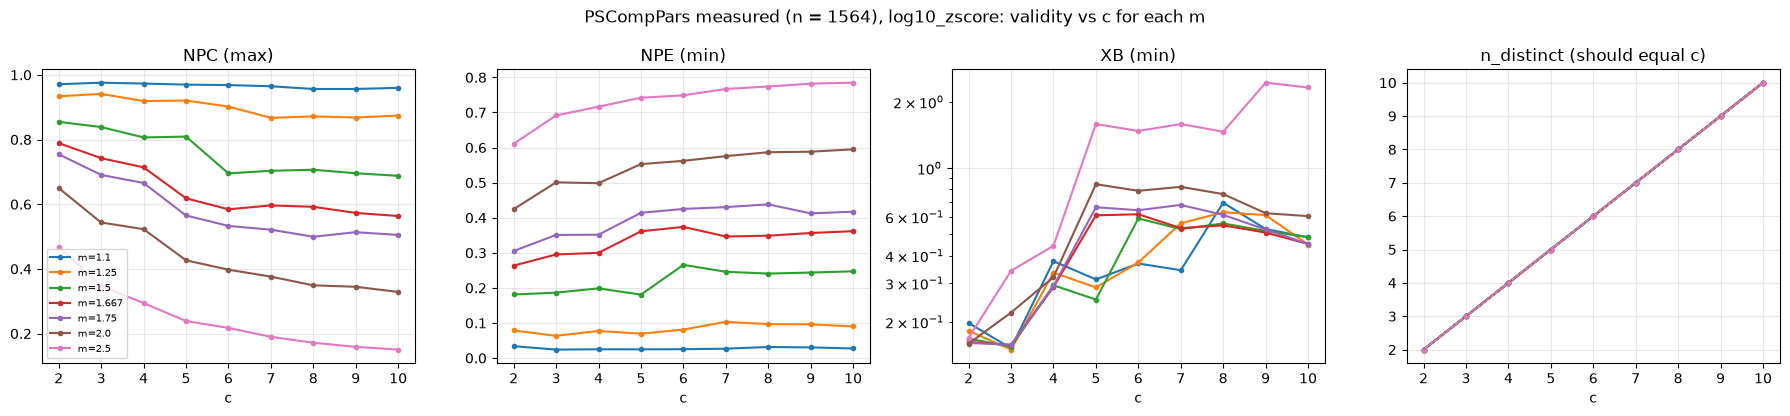

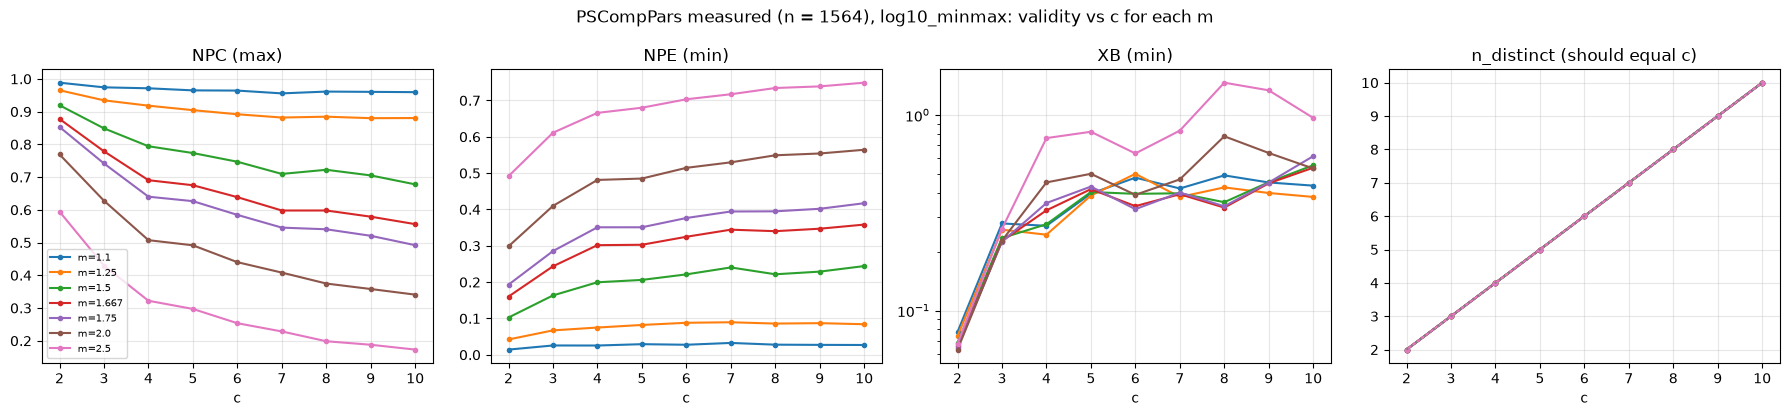

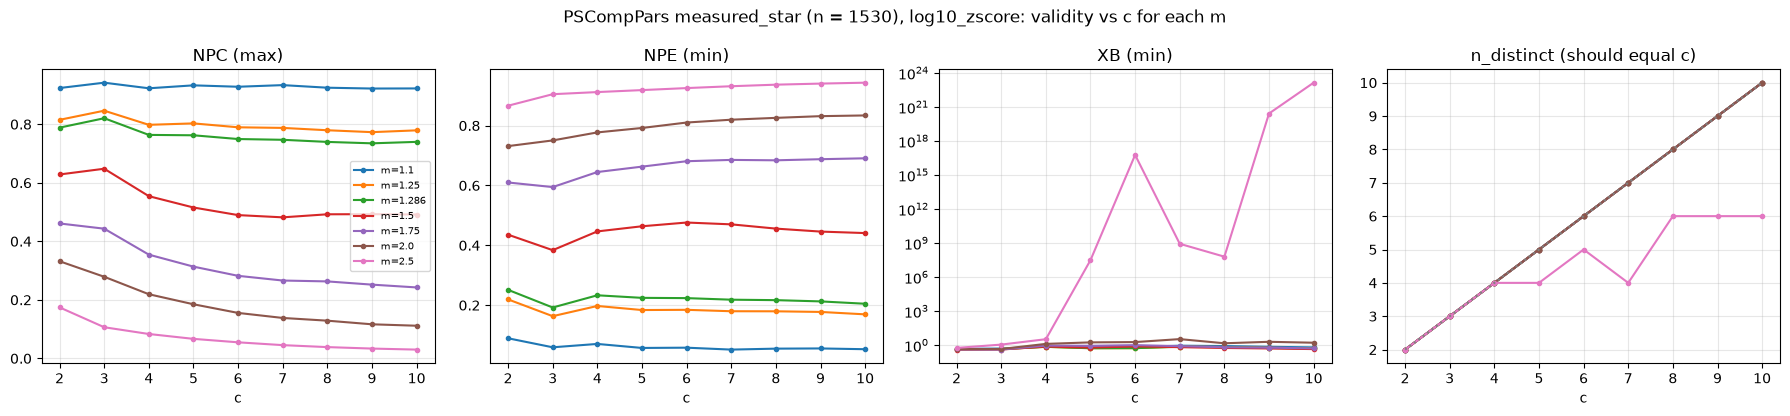

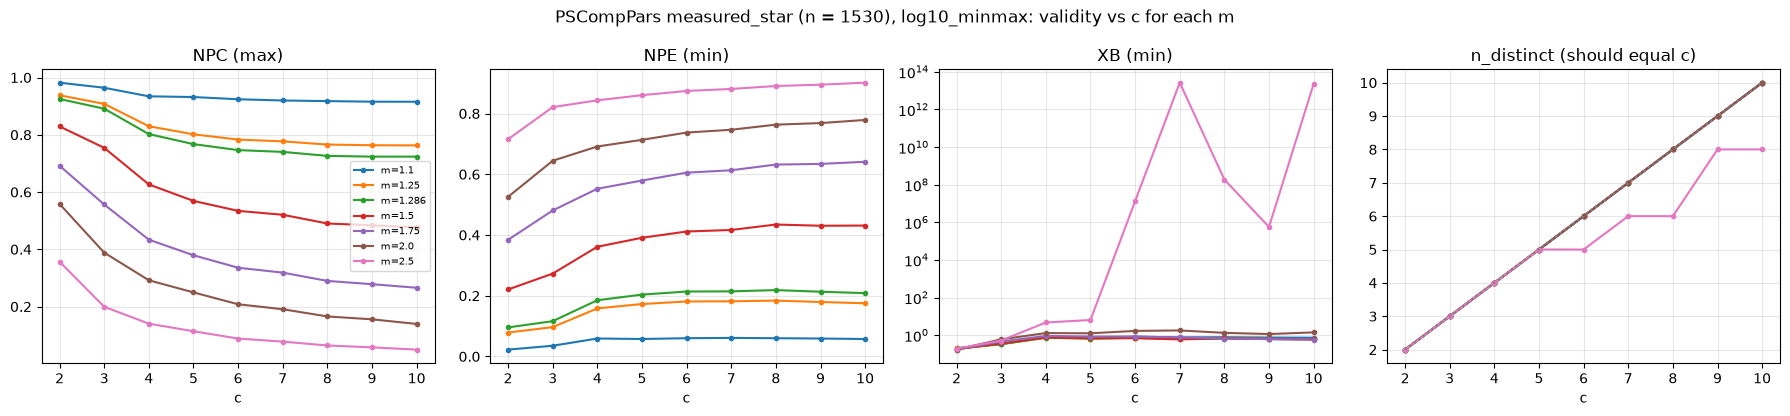

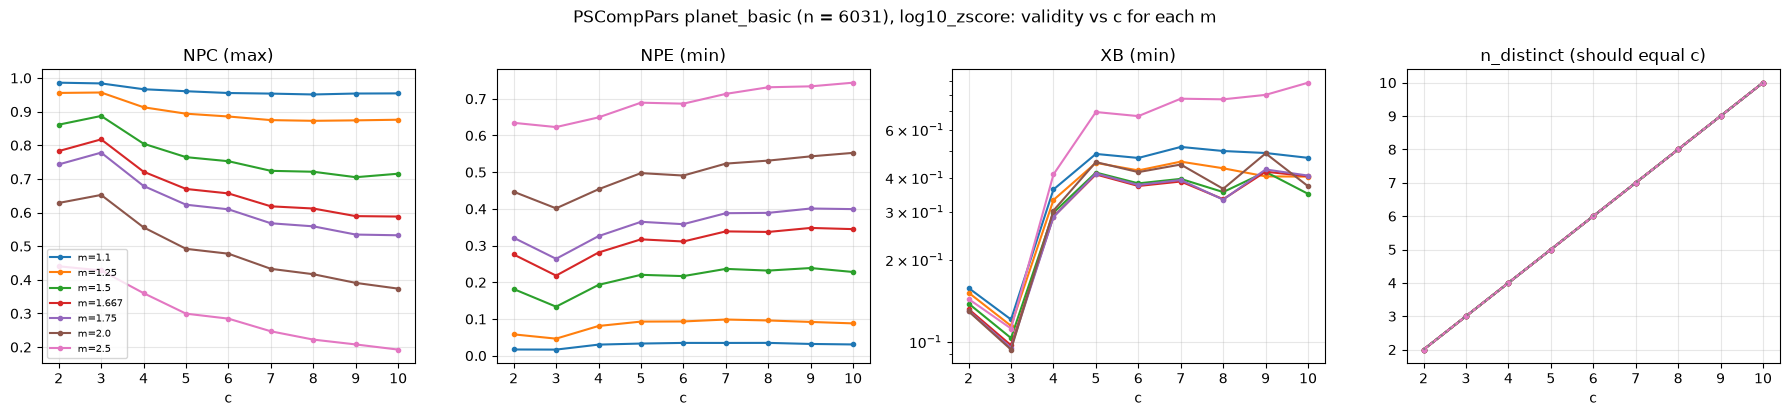

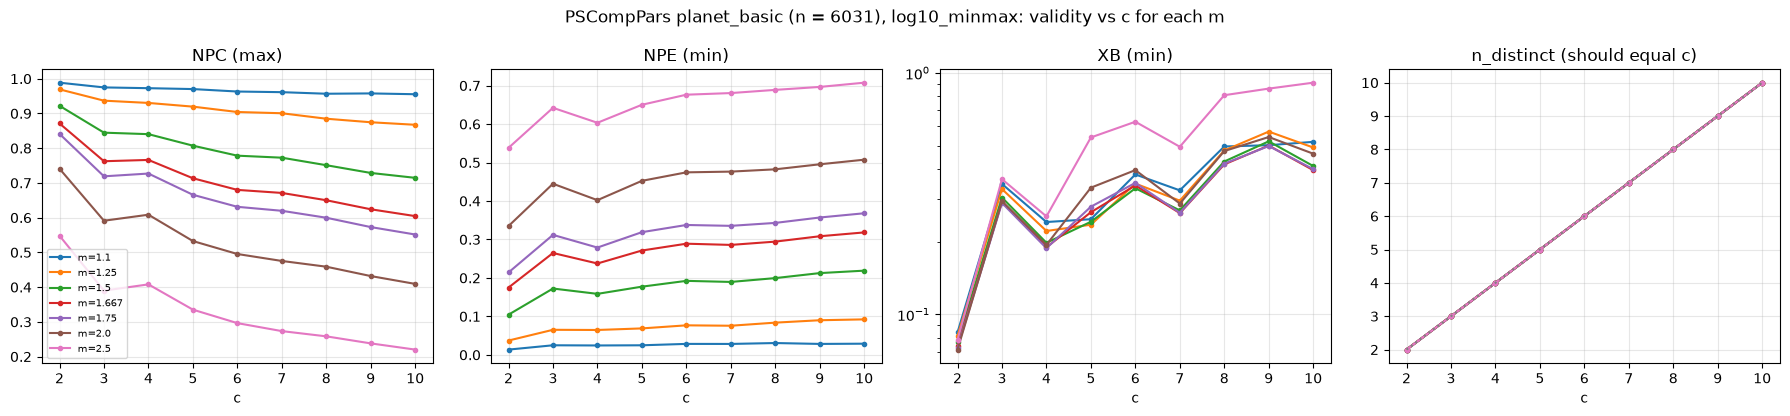

In [48]:
PANELS = [("NPC", "max", False), ("NPE", "min", False), ("XB", "min", True), ("n_distinct", "should equal c", False)]

for (tname, vname), g in grid.groupby(["table", "variant"], sort=False):
    fig, axes = plt.subplots(1, len(PANELS), figsize=(18, 4.2), sharex=True)
    for ax, (col, best_dir, logy) in zip(axes, PANELS):
        for m, gm in g.groupby("m"):
            ax.plot(gm["c"], gm[col], marker="o", markersize=3, label=f"m={m}")
        if col == "n_distinct":
            ax.plot(list(C_RANGE), list(C_RANGE), color="grey", linestyle=":", label="= c")
        if logy:
            ax.set_yscale("log")
        ax.set_title(f"{col} ({best_dir})")
        ax.set_xlabel("c")
        ax.set_xticks(list(C_RANGE))
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    fig.suptitle(f"PSCompPars {tname} (n = {len(tables[tname])}), {vname}: validity vs c for each m")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"pscomppars_c_m_grid_{tname}_{vname}.png", dpi=200)
    plt.show()

In [49]:
# For each (table, variant, m): the c preferred by each index, among non-degenerate partitions only
# (all c prototypes distinct). "-" means no valid c for that m.
pref_rows = []
for (tname, vname, m), g in grid.groupby(["table", "variant", "m"], sort=False):
    valid = g[g["n_distinct"] == g["c"]].set_index("c")
    row = {"table": tname, "variant": vname, "m": m, "valid c": ",".join(map(str, valid.index)) if len(valid) else "-"}
    for idx, d in INDICES.items():
        row[idx] = (valid[idx].idxmax() if d == "max" else valid[idx].idxmin()) if len(valid) else "-"
    pref_rows.append(row)
grid_pref = pd.DataFrame(pref_rows)
grid_pref.to_csv(OUT_DIR / "pscomppars_c_m_grid_preferred.csv", index=False)
grid_pref

,table,variant,m,valid c,PC,NPC,PE,NPE,XB,FS
0,measured,log10_zscore,1.100,"2,3,4,5,6,7,8,9,10",2,3,2,3,3,10
1,measured,log10_zscore,1.250,"2,3,4,5,6,7,8,9,10",2,3,2,3,3,10
2,measured,log10_zscore,1.500,"2,3,4,5,6,7,8,9,10",2,2,2,5,3,10
3,measured,log10_zscore,1.667,"2,3,4,5,6,7,8,9,10",2,2,2,2,3,10
4,measured,log10_zscore,1.750,"2,3,4,5,6,7,8,9,10",2,2,2,2,3,10
5,measured,log10_zscore,2.000,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,4
6,measured,log10_zscore,2.500,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,4
7,measured,log10_minmax,1.100,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,10
8,measured,log10_minmax,1.250,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,10
9,measured,log10_minmax,1.500,"2,3,4,5,6,7,8,9,10",2,2,2,2,2,9


In [50]:
# Stability: how many of the 10 starts reached the best minimum, per (table, variant, c), at m = 2 and m = 1.5
(grid[grid["m"].isin([1.5, 2.0])]
   .pivot_table(index=["table", "variant", "m"], columns="c", values="n_at_best"))

c                                 2     3     4     5     6     7     8   \
table         variant      m                                               
measured      log10_minmax 1.5  10.0  10.0  10.0  10.0  10.0  10.0   3.0   
                           2.0  10.0  10.0  10.0  10.0  10.0  10.0   4.0   
              log10_zscore 1.5  10.0  10.0  10.0   1.0  10.0   3.0  10.0   
                           2.0  10.0  10.0  10.0   8.0  10.0   6.0  10.0   
measured_star log10_minmax 1.5  10.0  10.0  10.0  10.0  10.0  10.0   7.0   
                           2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
              log10_zscore 1.5  10.0  10.0  10.0   9.0   2.0   4.0   8.0   
                           2.0  10.0  10.0  10.0  10.0  10.0  10.0  10.0   
planet_basic  log10_minmax 1.5  10.0   8.0  10.0  10.0   9.0   2.0  10.0   
                           2.0  10.0   9.0  10.0  10.0  10.0   5.0  10.0   
              log10_zscore 1.5  10.0  10.0  10.0  10.0   9.0  10.0  10.0   
                           2.0  10.0  10.0  10.0  10.0  10.0  10.0   7.0   

c                                 9     10  
table         variant      m                
measured      log10_minmax 1.5  10.0   6.0  
                           2.0  10.0  10.0  
              log10_zscore 1.5   8.0   5.0  
                           2.0   2.0   5.0  
measured_star log10_minmax 1.5  10.0   4.0  
                           2.0  10.0  10.0  
              log10_zscore 1.5   6.0   8.0  
                           2.0  10.0  10.0  
planet_basic  log10_minmax 1.5  10.0   9.0  
                           2.0  10.0  10.0  
              log10_zscore 1.5   4.0   3.0  
                           2.0  10.0   1.0

## Step 9: Looking at the c = 2 and c = 3 partitions

The best runs of Step 8 (lowest J of 10 starts) for c in {2, 3}, m in {1.5, 2}, both preprocessing variants,
on `measured` (main) and `planet_basic` (comparison). Hard labels = cluster of largest membership.
Cluster numbers are reordered by the prototype's radius (cluster 0 = smallest radius), so that the same number
means a comparable cluster across runs.

- **9a** prototypes in physical units and cluster sizes
- **9b** agreement between partitions (ARI): z-score vs min-max, m = 2 vs m = 1.5
- **9c** partitions in the mass–radius and period–radius planes (`measured`)
- **9d** membership distributions
- **9e** where the special cases end up (Imaging planets, KOI-2513.01, very uncertain masses)
- **9f** `planet_basic`: partitions vs the origin of the values (measured / calculated)

In [51]:
from sklearn.metrics import adjusted_rand_score

PART_TABLES, PART_M, PART_C = ["measured", "planet_basic"], [2.0, 1.5], [2, 3]

def to_physical(tname, vname, V):
    """Prototypes from the scaled space back to physical units (inverse scaling, then 10**x except st_met)."""
    cols = FEATURE_SETS[tname]
    L = log_view(tables[tname], cols).to_numpy(dtype=float)
    if vname == "log10_zscore":
        Vl = V * L.std(axis=0) + L.mean(axis=0)
    else:
        Vl = V * (L.max(axis=0) - L.min(axis=0)) + L.min(axis=0)
    phys = pd.DataFrame(Vl, columns=cols)
    for c in cols:
        if c not in NOT_LOGGED:
            phys[c] = 10 ** phys[c]
    return phys

parts = {}          # (table, variant, m, c) -> dict(labels, maxu, U) with clusters ordered by prototype radius
proto_rows = []
for tname in PART_TABLES:
    for vname in VARIANTS:
        for m in PART_M:
            for c in PART_C:
                res = grid_runs[(tname, vname, m, c)]
                phys = to_physical(tname, vname, res.V)
                order = np.argsort(phys["pl_rade"].to_numpy())          # new cluster k = old cluster order[k]
                U = res.U[order]
                labels = U.argmax(axis=0)
                parts[(tname, vname, m, c)] = {"U": U, "labels": labels, "maxu": U.max(axis=0)}
                phys = phys.iloc[order].reset_index(drop=True)
                for k in range(c):
                    proto_rows.append({"table": tname, "variant": vname, "m": m, "c": c, "cluster": k,
                                       "size": int((labels == k).sum()),
                                       "mean max u": round(float(U.max(axis=0)[labels == k].mean()), 3),
                                       **phys.iloc[k].round(3).to_dict()})
protos = pd.DataFrame(proto_rows)
protos.to_csv(OUT_DIR / "pscomppars_partitions_prototypes.csv", index=False)
protos

,table,variant,m,c,cluster,size,mean max u,pl_orbper,pl_rade,pl_bmasse
0,measured,log10_zscore,2.0,2,0,721,0.867,9.572,2.453,8.257
1,measured,log10_zscore,2.0,2,1,843,0.898,4.799,12.677,293.540
2,measured,log10_zscore,2.0,3,0,526,0.773,5.996,2.079,6.152
3,measured,log10_zscore,2.0,3,1,303,0.628,34.497,5.018,34.086
4,measured,log10_zscore,2.0,3,2,735,0.868,3.774,13.395,321.677
5,measured,log10_zscore,1.5,2,0,715,0.947,9.332,2.431,8.094
6,measured,log10_zscore,1.5,2,1,849,0.953,5.263,12.718,303.743
7,measured,log10_zscore,1.5,3,0,647,0.924,7.061,2.214,6.812
8,measured,log10_zscore,1.5,3,1,181,0.827,86.201,7.716,106.523
9,measured,log10_zscore,1.5,3,2,736,0.959,3.707,13.152,310.105


### 9b. Agreement between partitions (adjusted Rand index; 1 = identical, about 0 = no better than chance)

In [52]:
agree = []
for tname in PART_TABLES:
    for c in PART_C:
        for m in PART_M:
            agree.append({"table": tname, "c": c, "comparison": f"zscore vs minmax (m={m})",
                          "ARI": adjusted_rand_score(parts[(tname, "log10_zscore", m, c)]["labels"],
                                                     parts[(tname, "log10_minmax", m, c)]["labels"])})
        for vname in VARIANTS:
            agree.append({"table": tname, "c": c, "comparison": f"m=2 vs m=1.5 ({vname})",
                          "ARI": adjusted_rand_score(parts[(tname, vname, 2.0, c)]["labels"],
                                                     parts[(tname, vname, 1.5, c)]["labels"])})
        if c == 3:
            for vname in VARIANTS:
                agree.append({"table": tname, "c": c, "comparison": f"c=2 vs c=3 (m=2, {vname})",
                              "ARI": adjusted_rand_score(parts[(tname, vname, 2.0, 2)]["labels"],
                                                         parts[(tname, vname, 2.0, 3)]["labels"])})
agree = pd.DataFrame(agree).round(3)
agree.to_csv(OUT_DIR / "pscomppars_partitions_agreement.csv", index=False)
agree

,table,c,comparison,ARI
0,measured,2,zscore vs minmax (m=2.0),0.910
1,measured,2,zscore vs minmax (m=1.5),0.925
2,measured,2,m=2 vs m=1.5 (log10_zscore),0.985
3,measured,2,m=2 vs m=1.5 (log10_minmax),1.000
4,measured,3,zscore vs minmax (m=2.0),0.642
5,measured,3,zscore vs minmax (m=1.5),0.591
6,measured,3,m=2 vs m=1.5 (log10_zscore),0.811
7,measured,3,m=2 vs m=1.5 (log10_minmax),0.958
8,measured,3,"c=2 vs c=3 (m=2, log10_zscore)",0.668
9,measured,3,"c=2 vs c=3 (m=2, log10_minmax)",0.691


### 9c. Partitions of `measured` in the physical planes

Colour = hard cluster, transparency = largest membership (faint points are shared between clusters),
black crosses = prototypes.

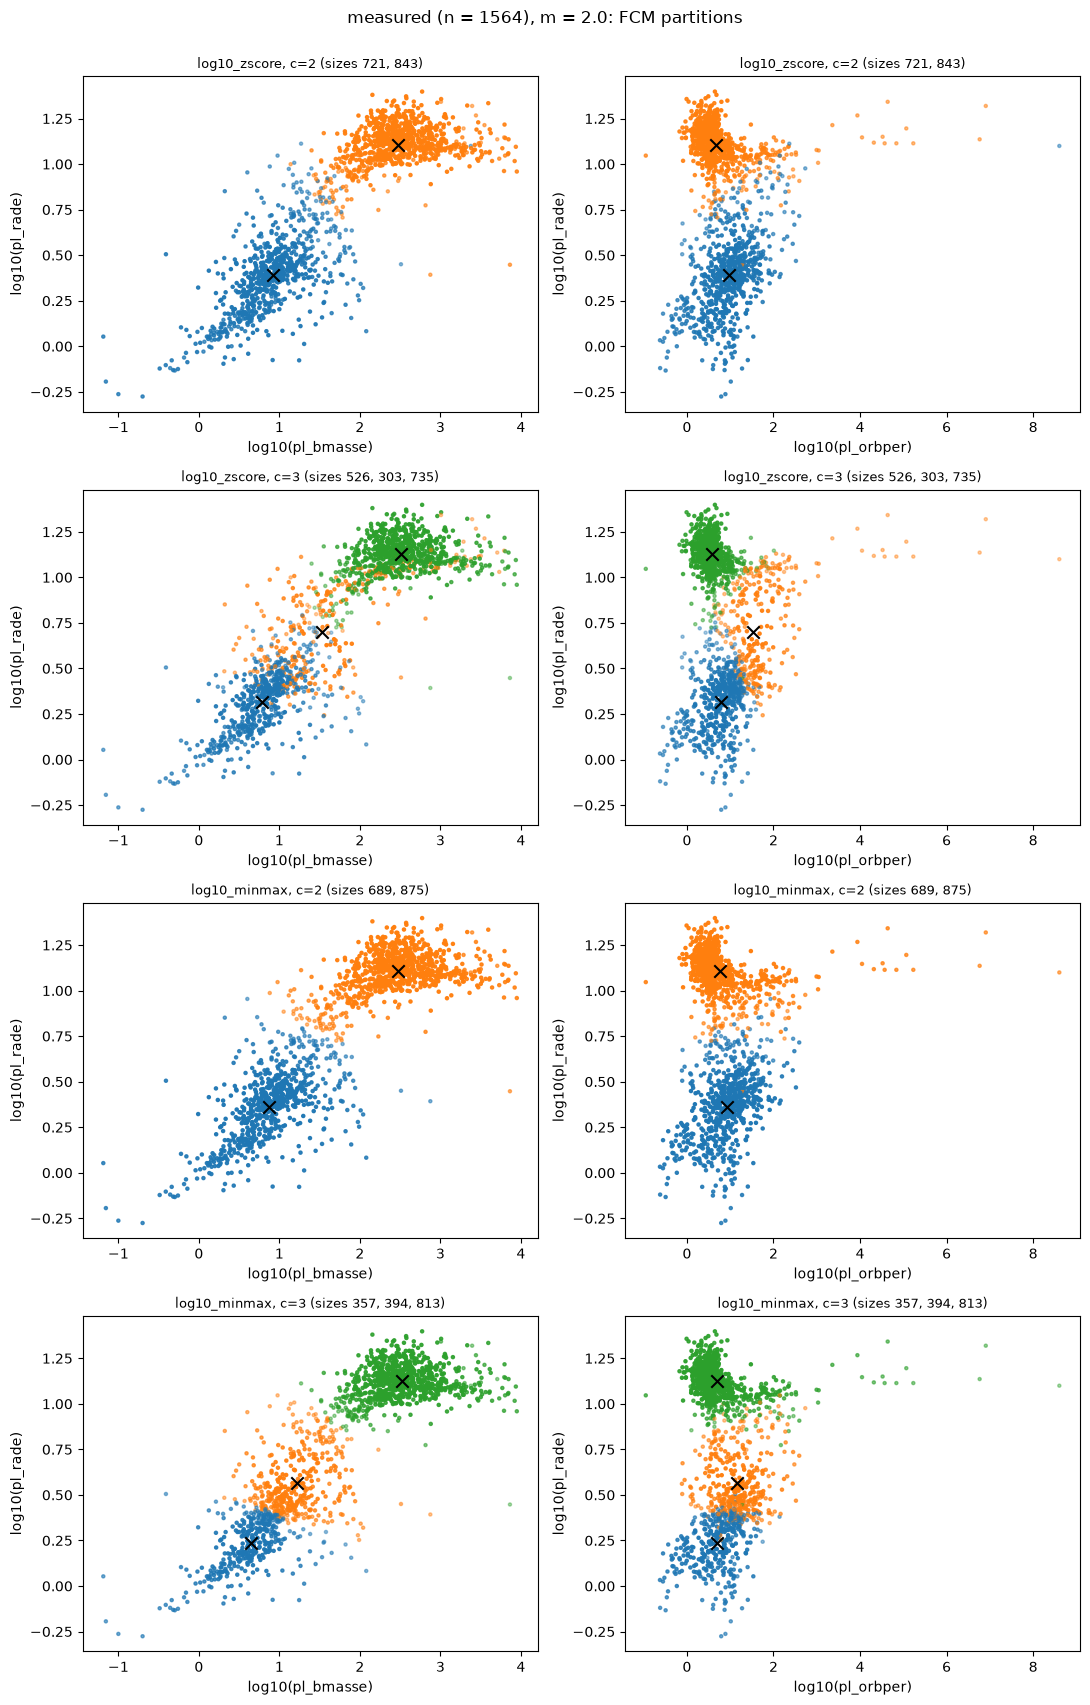

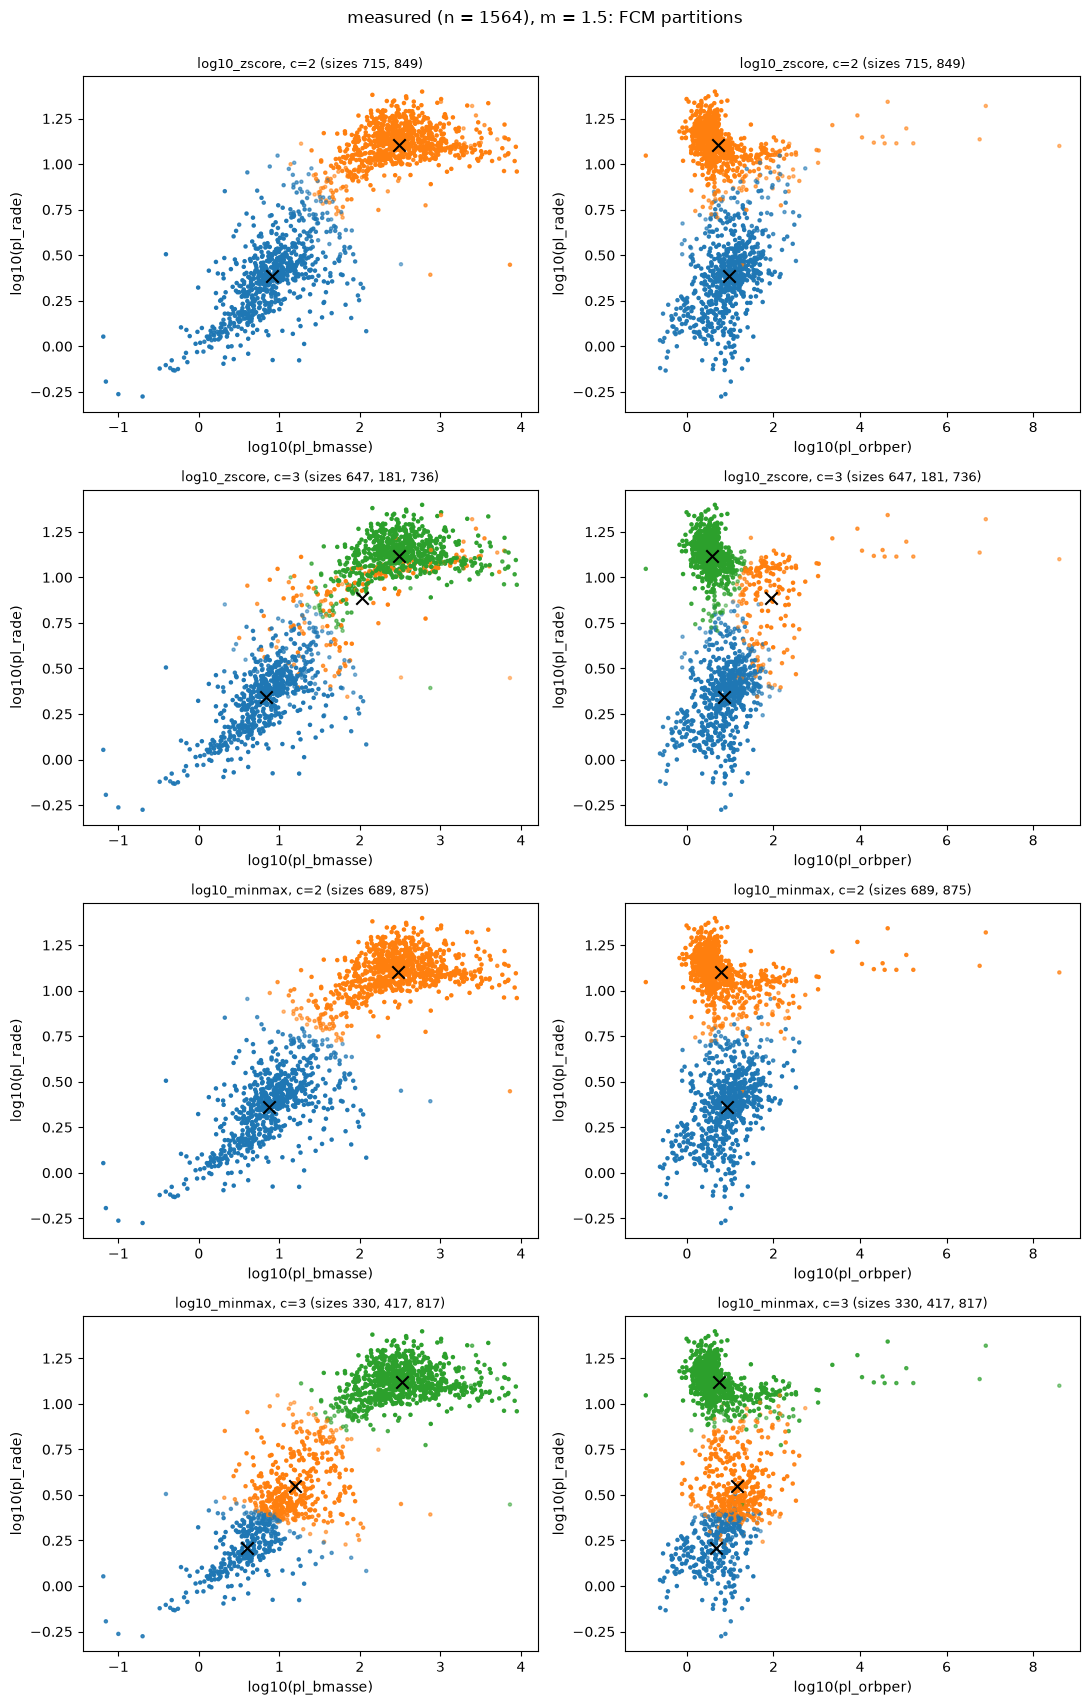

In [53]:
t = tables["measured"]
lx = {c: np.log10(t[c]) for c in FEATURE_SETS["measured"]}
PLANES = [("pl_bmasse", "pl_rade"), ("pl_orbper", "pl_rade")]
import matplotlib.colors as mcolors
COLORS = np.array(["tab:blue", "tab:orange", "tab:green"])

for m in PART_M:
    fig, axes = plt.subplots(4, 2, figsize=(11, 17))
    for r, (vname, c) in enumerate([(v, c) for v in VARIANTS for c in PART_C]):
        P = parts[("measured", vname, m, c)]
        phys = protos.query("table == 'measured' and variant == @vname and m == @m and c == @c")
        for j, (xc, yc) in enumerate(PLANES):
            ax = axes[r, j]
            rgba = [(*mcolors.to_rgb(col), a) for col, a in zip(COLORS[P["labels"]], P["maxu"])]
            ax.scatter(lx[xc], lx[yc], s=5, c=rgba)
            ax.scatter(np.log10(phys[xc]), np.log10(phys[yc]), marker="x", s=80, color="black")
            ax.set_xlabel(f"log10({xc})")
            ax.set_ylabel(f"log10({yc})")
            sizes = ", ".join(map(str, phys["size"]))
            ax.set_title(f"{vname}, c={c} (sizes {sizes})", fontsize=9)
    fig.suptitle(f"measured (n = {len(t)}), m = {m}: FCM partitions", y=1.0)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"pscomppars_measured_partitions_m{m}.png", dpi=200)
    plt.show()

### 9d. Membership distributions (largest membership of each planet)

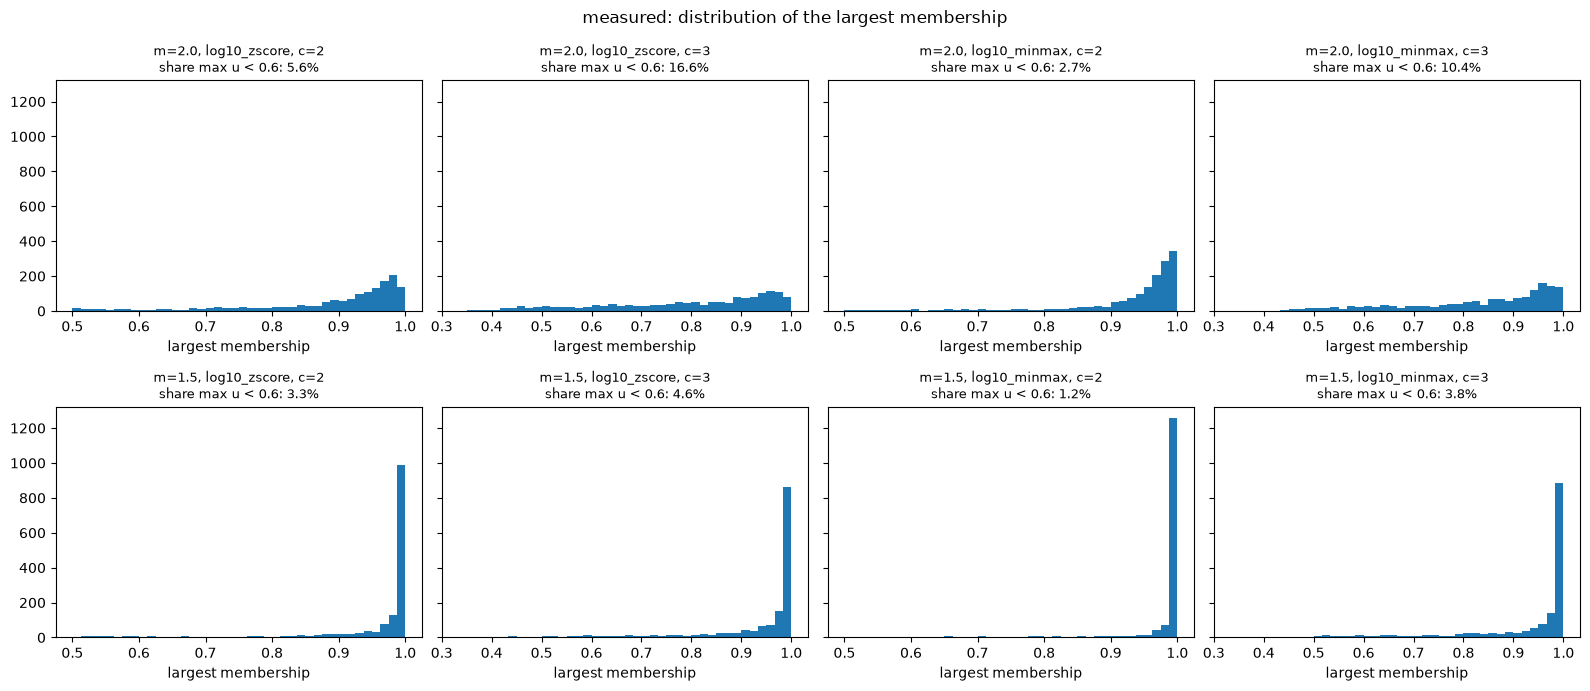

In [54]:
fig, axes = plt.subplots(len(PART_M), 4, figsize=(16, 3.5 * len(PART_M)), sharey=True)
for i, m in enumerate(PART_M):
    for j, (vname, c) in enumerate([(v, c) for v in VARIANTS for c in PART_C]):
        maxu = parts[("measured", vname, m, c)]["maxu"]
        axes[i, j].hist(maxu, bins=40, range=(1 / c, 1))
        axes[i, j].set_title(f"m={m}, {vname}, c={c}\nshare max u < 0.6: {(maxu < 0.6).mean():.1%}", fontsize=9)
        axes[i, j].set_xlabel("largest membership")
fig.suptitle("measured: distribution of the largest membership")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_measured_membership_hist.png", dpi=200)
plt.show()

### 9e. Special cases

Groups (a planet can be in more than one): Imaging planets, other non-transit methods, KOI-2513.01, and planets
whose relative mass uncertainty is above 0.5. For each partition: in which clusters they are and how strongly they belong.

In [55]:
t = tables["measured"]
rel_mass = ru.loc[measured_mask, "pl_bmasse"].to_numpy()
special = {
    "Imaging": t["discoverymethod"].eq("Imaging").to_numpy(),
    "other non-transit": (~t["discoverymethod"].isin(["Transit", "Imaging"])).to_numpy(),
    "KOI-2513.01": t["pl_name"].eq("KOI-2513.01").to_numpy(),
    "mass rel. unc. > 0.5": rel_mass > 0.5,
    "all measured": np.ones(len(t), dtype=bool),
}
rows = []
for (tname, vname, m, c), P in parts.items():
    if tname != "measured":
        continue
    for gname, sel in special.items():
        row = {"variant": vname, "m": m, "c": c, "group": gname, "n": int(sel.sum()),
               "mean max u": round(float(P["maxu"][sel].mean()), 3)}
        for k in range(c):
            row[f"in cluster {k}"] = int((P["labels"][sel] == k).sum())
        rows.append(row)
special_tab = pd.DataFrame(rows)
special_tab.to_csv(OUT_DIR / "pscomppars_measured_special_cases.csv", index=False)
special_tab.query("m == 2.0")

,variant,m,c,group,n,mean max u,in cluster 0,in cluster 1,in cluster 2
0,log10_zscore,2.0,2,Imaging,13,0.533,1,12,NaN
1,log10_zscore,2.0,2,other non-transit,31,0.870,23,8,NaN
2,log10_zscore,2.0,2,KOI-2513.01,1,0.642,0,1,NaN
3,log10_zscore,2.0,2,mass rel. unc. > 0.5,113,0.857,101,12,NaN
4,log10_zscore,2.0,2,all measured,1564,0.884,721,843,NaN
5,log10_zscore,2.0,3,Imaging,13,0.427,0,13,0.0
6,log10_zscore,2.0,3,other non-transit,31,0.766,16,8,7.0
7,log10_zscore,2.0,3,KOI-2513.01,1,0.414,0,0,1.0
8,log10_zscore,2.0,3,mass rel. unc. > 0.5,113,0.697,67,37,9.0
9,log10_zscore,2.0,3,all measured,1564,0.790,526,303,735.0


In [56]:
# The Imaging planets one by one (m = 2, z-score, c = 2 and 3)
cols = ["pl_name", "pl_orbper", "pl_rade", "pl_bmasse"]
img = t.loc[special["Imaging"], cols].copy()
for c in PART_C:
    P = parts[("measured", "log10_zscore", 2.0, c)]
    img[f"cluster (c={c})"] = P["labels"][special["Imaging"]]
    img[f"max u (c={c})"] = P["maxu"][special["Imaging"]].round(3)
img.sort_values("pl_orbper")

,pl_name,pl_orbper,pl_rade,pl_bmasse,cluster (c=2),max u (c=2),cluster (c=3),max u (c=3)
240,HD 206893 c,2290.0,16.365112,3527.895318,1,0.590,1,0.449
1562,bet Pic b,8682.0,18.494850,2765.107141,1,0.562,1,0.443
239,HD 206893 b,11100.0,14.011226,6197.653936,1,0.557,1,0.437
308,HR 8799 e,20815.6,13.114530,3178.300000,1,0.540,1,0.440
1563,bet Pic d,33200.0,14.123316,762.788177,1,0.523,1,0.447
307,HR 8799 d,37000.0,13.000000,3000.000000,1,0.533,1,0.436
818,PDS 70 b,43500.0,21.969602,1017.050902,1,0.534,1,0.436
306,HR 8799 c,69000.0,13.000000,3000.000000,1,0.527,1,0.431
222,HD 143811 AB b,117000.0,15.692573,1938.753283,1,0.523,1,0.427
305,HR 8799 b,170000.0,13.000000,2000.000000,1,0.517,1,0.426


### 9f. `planet_basic`: clusters vs the origin of the values

In Step 6b, 70 % of the `planet_basic` rows lie on the archive's mass–radius curve (calculated values).
How are those rows distributed over the clusters?

In [57]:
origin = group[basic].to_numpy()          # Step 6b groups, in the row order of tables["planet_basic"]
rows = []
for (tname, vname, m, c), P in parts.items():
    if tname != "planet_basic" or m != 2.0:
        continue
    ct = pd.crosstab(origin, P["labels"])
    ct.columns = [f"cluster {k}" for k in ct.columns]
    ct.insert(0, "partition", f"{vname}, c={c}")
    rows.append(ct)
origin_tab = pd.concat(rows)
origin_tab.to_csv(OUT_DIR / "pscomppars_planet_basic_clusters_by_origin.csv", index_label="origin")
origin_tab

,partition,cluster 0,cluster 1,cluster 2
row_0,,,,
mass calculated from radius,"log10_zscore, c=2",2957,77,NaN
measured (main table),"log10_zscore, c=2",709,855,NaN
"other (Msini, limits, ...)","log10_zscore, c=2",158,57,NaN
radius calculated from mass,"log10_zscore, c=2",333,885,NaN
mass calculated from radius,"log10_zscore, c=3",2916,97,21.0
measured (main table),"log10_zscore, c=3",660,842,62.0
"other (Msini, limits, ...)","log10_zscore, c=3",148,53,14.0
radius calculated from mass,"log10_zscore, c=3",331,134,753.0
mass calculated from radius,"log10_minmax, c=2",2939,95,NaN


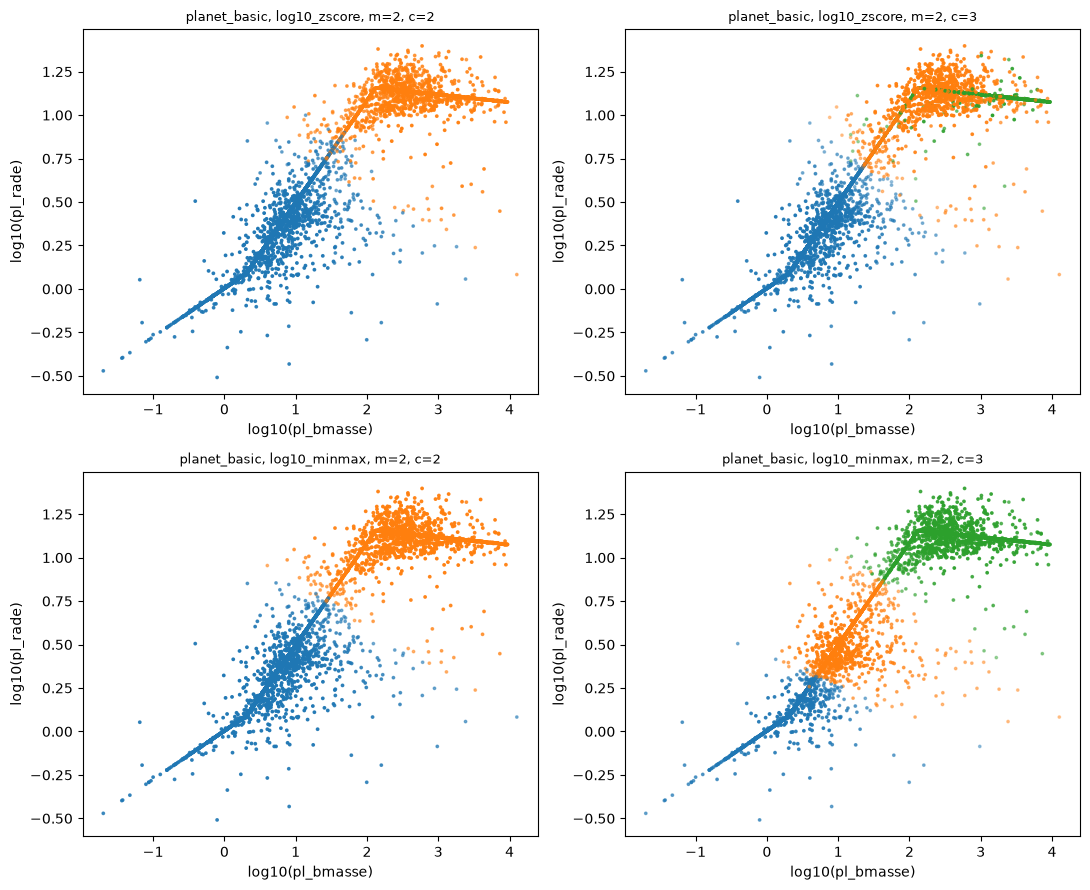

In [58]:
tb = tables["planet_basic"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (vname, c) in zip(axes.ravel(), [(v, c) for v in VARIANTS for c in PART_C]):
    P = parts[("planet_basic", vname, 2.0, c)]
    rgba = [(*mcolors.to_rgb(col), a) for col, a in zip(COLORS[P["labels"]], P["maxu"])]
    ax.scatter(np.log10(tb["pl_bmasse"]), np.log10(tb["pl_rade"]), s=3, c=rgba)
    ax.set_title(f"planet_basic, {vname}, m=2, c={c}", fontsize=9)
    ax.set_xlabel("log10(pl_bmasse)")
    ax.set_ylabel("log10(pl_rade)")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_planet_basic_partitions_m2.png", dpi=200)
plt.show()

## Step 10: Possibilistic c-means (PCM) started from FCM

In Step 9e the Imaging planets, far from both prototypes, got FCM memberships close to 0.5: FCM memberships sum to 1
over the clusters, so they express *sharing*, not *typicality*. PCM (lecture 05a, slides 21-23; Krishnapuram & Keller
1993, 1996, `Papers/krishnapuram1996.pdf`) drops that constraint. Same recipe as for WDBC: (1) FCM, (2) eta_i from the
FCM result, (3) PCM from the FCM prototypes with eta fixed. Configuration: `measured`, c = 2, m = 2, both variants.

Checked: do the PCM prototypes stay apart (coincident clusters are the known PCM weakness)? Which planets are
atypical of both clusters (largest typicality < 0.5)?

In [66]:
C_MAIN, M_MAIN = 2, 2.0
t = tables["measured"]
pcm_runs, pcm_rows = {}, []
for vname in VARIANTS:
    A = data[("measured", vname)]
    res_f = grid_runs[("measured", vname, M_MAIN, C_MAIN)]
    eta = fcm.pcm_eta(A, res_f.U, res_f.V, M_MAIN)
    res_p = fcm.pcm(A, res_f.V, eta, m=M_MAIN, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
    pcm_runs[vname] = (res_f, res_p, eta)
    for alg, res in (("FCM", res_f), ("PCM", res_p)):
        phys = to_physical("measured", vname, res.V).sort_values("pl_rade").round(3)
        pcm_rows.append({"variant": vname, "algorithm": alg, "iterations": res.n_iter, "converged": res.converged,
                         "prototype distance": round(fcm.prototype_diagnostics(A, res)["min_proto_dist"], 4),
                         "eta": np.round(np.sort(eta), 4).tolist() if alg == "PCM" else "",
                         "prototypes (P, R, M)": phys.values.tolist(),
                         "cluster sizes": np.bincount(res.labels, minlength=C_MAIN).tolist()})
    print(f"{vname}: ARI between FCM and PCM hard labels = {adjusted_rand_score(res_f.labels, res_p.labels):.4f}")
pcm_summary = pd.DataFrame(pcm_rows)
pcm_summary.to_csv(OUT_DIR / "pscomppars_measured_pcm_vs_fcm.csv", index=False)
pcm_summary

log10_zscore: ARI between FCM and PCM hard labels = -0.0033
log10_minmax: ARI between FCM and PCM hard labels = 0.9100


,variant,algorithm,iterations,converged,prototype distance,eta,"prototypes (P, R, M)",cluster sizes
0,log10_zscore,FCM,17,True,2.5029,,"[[9.572, 2.453, 8.257], [4.799, 12.677, 293.54]]","[843, 721]"
1,log10_zscore,PCM,110,True,0.0676,"[1.043, 1.416]","[[4.101, 12.146, 217.055], [3.9, 12.681, 234.22]]","[92, 1472]"
2,log10_minmax,FCM,15,True,0.5438,,"[[8.289, 2.297, 7.45], [5.661, 12.754, 299.505]]","[875, 689]"
3,log10_minmax,PCM,25,True,0.5034,"[0.0184, 0.0246]","[[9.869, 2.681, 9.626], [4.074, 13.232, 274.092]]","[839, 725]"


In [67]:
# Point level: largest FCM membership vs largest PCM typicality.
# Done on the min-max run: with z-score the two PCM prototypes became coincident (cell above), so its
# typicalities measure the distance to the giant-planet prototype only, not atypicality with respect to both clusters.
for v, (rf, rp, _) in pcm_runs.items():
    print(f"{v}: PCM prototype distance {fcm.prototype_diagnostics(data[('measured', v)], rp)['min_proto_dist']:.3f}, "
          f"planets with largest typicality < 0.5: {int((rp.U.max(axis=0) < 0.5).sum())}")
print()

vname = "log10_minmax"
res_f, res_p, eta = pcm_runs[vname]
A = data[("measured", vname)]
pts = t[["pl_name", "discoverymethod", "pl_orbper", "pl_rade", "pl_bmasse"]].copy()
pts["fcm_max_u"] = res_f.U.max(axis=0)
pts["pcm_max_t"] = res_p.U.max(axis=0)
pts["dist_to_nearest_proto"] = np.sqrt(fcm.squared_distances(A, res_p.V).min(axis=0))
pts["mass_rel_unc"] = rel_mass
pts.to_csv(OUT_DIR / "pscomppars_measured_pcm_points.csv", index=False)

print("atypical of both clusters (largest typicality < 0.5):", int((pts["pcm_max_t"] < 0.5).sum()), "of", len(pts))
print("\nlargest typicality by group:")
print(pd.DataFrame({g: pts.loc[sel, "pcm_max_t"].describe()[["count", "mean", "min", "50%"]]
                    for g, sel in special.items()}).T.round(3))
print("\natypical planets by discovery method:")
print(pts.loc[pts["pcm_max_t"] < 0.5, "discoverymethod"].value_counts())
print("\n20 most atypical planets:")
pts.sort_values("pcm_max_t").head(20).round(3)

log10_zscore: PCM prototype distance 0.068, planets with largest typicality < 0.5: 863
log10_minmax: PCM prototype distance 0.503, planets with largest typicality < 0.5: 504

atypical of both clusters (largest typicality < 0.5): 504 of 1564

largest typicality by group:
                       count   mean    min    50%
Imaging                 13.0  0.073  0.024  0.080
other non-transit       31.0  0.577  0.108  0.522
KOI-2513.01              1.0  0.072  0.072  0.072
mass rel. unc. > 0.5   113.0  0.515  0.072  0.496
all measured          1564.0  0.627  0.024  0.661

atypical planets by discovery method:
discoverymethod
Transit                          479
Imaging                           13
Radial Velocity                   10
Orbital Brightness Modulation      2
Name: count, dtype: int64

20 most atypical planets:


,pl_name,discoverymethod,pl_orbper,pl_rade,pl_bmasse,fcm_max_u,pcm_max_t,dist_to_nearest_proto,mass_rel_unc
6,COCONUTS-2 b,Imaging,4.020000e+08,12.576,2383.713,0.605,0.024,0.857,0.053
5,CFHTWIR-Oph 98 b,Imaging,8.040000e+06,20.849,2479.062,0.675,0.037,0.695,0.096
1373,VHS J125601.92-125723.9 b,Imaging,5.800000e+06,13.675,5085.255,0.663,0.037,0.690,0.062
305,HR 8799 b,Imaging,1.700000e+05,13.000,2000.000,0.720,0.065,0.512,0.400
222,HD 143811 AB b,Imaging,1.170000e+05,15.693,1938.753,0.740,0.069,0.497,0.131
664,Kepler-444 e,Transit,7.743000e+00,0.546,0.100,0.806,0.072,0.565,1.500
306,HR 8799 c,Imaging,6.900000e+04,13.000,3000.000,0.740,0.072,0.487,0.333
432,KOI-2513.01,Transit,1.900500e+01,2.802,7310.053,0.598,0.072,0.494,0.087
482,Kepler-138 b,Transit,1.031300e+01,0.640,0.070,0.806,0.073,0.558,0.286
307,HR 8799 d,Imaging,3.700000e+04,13.000,3000.000,0.754,0.080,0.461,0.333


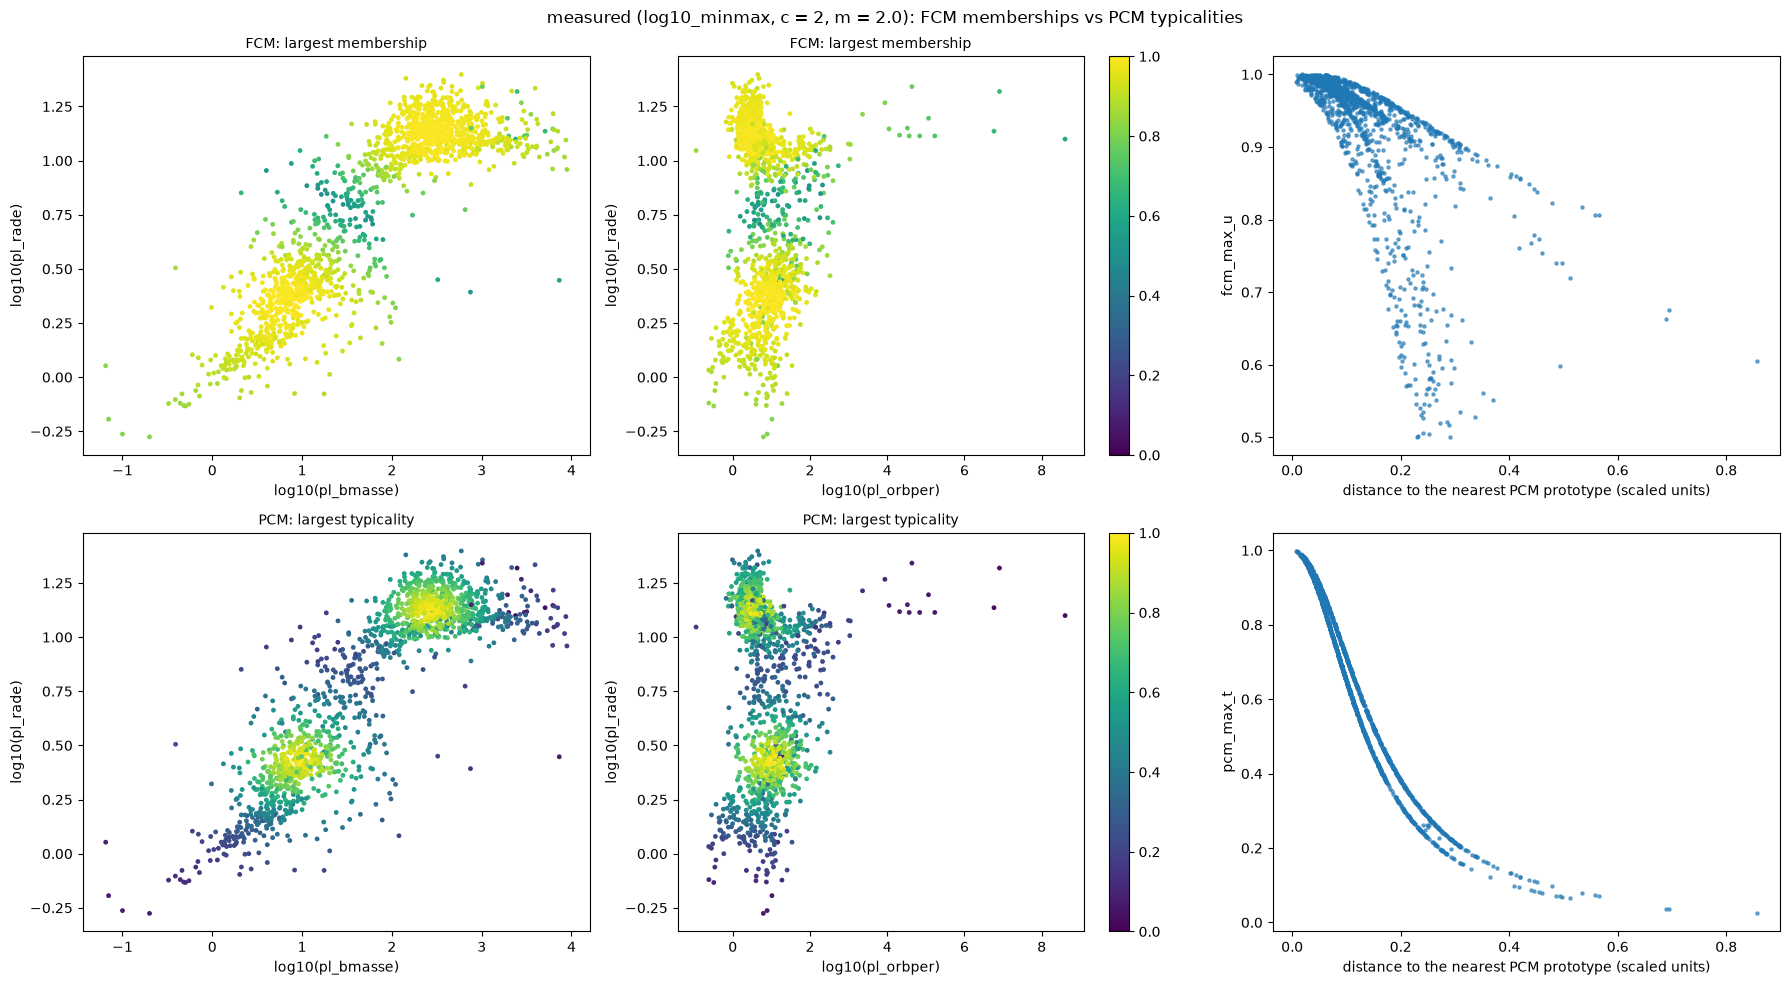

In [68]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
lx = {c: np.log10(t[c]) for c in FEATURE_SETS["measured"]}
for r, (col, title) in enumerate([("fcm_max_u", "FCM: largest membership"), ("pcm_max_t", "PCM: largest typicality")]):
    for j, (xc, yc) in enumerate(PLANES):
        ax = axes[r, j]
        sc = ax.scatter(lx[xc], lx[yc], c=pts[col], cmap="viridis", vmin=0, vmax=1, s=6)
        ax.set_xlabel(f"log10({xc})")
        ax.set_ylabel(f"log10({yc})")
        ax.set_title(title, fontsize=10)
    fig.colorbar(sc, ax=axes[r, 1])
for r, col in enumerate(["fcm_max_u", "pcm_max_t"]):
    ax = axes[r, 2]
    ax.scatter(pts["dist_to_nearest_proto"], pts[col], s=5, alpha=0.6)
    ax.set_xlabel("distance to the nearest PCM prototype (scaled units)")
    ax.set_ylabel(col)
fig.suptitle(f"measured ({vname}, c = {C_MAIN}, m = {M_MAIN}): FCM memberships vs PCM typicalities")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_measured_pcm_vs_fcm.png", dpi=200)
plt.show()

## Step 11: Does adding the host star change the partition? (`measured_star`)

The same c = 2 and c = 3 runs (m = 2 and 1.5, both variants) on the 1,530 planets that also have the four stellar
features. Compared with the `measured` partition of the same planets (matched by name) using ARI.

In [69]:
def ordered_partition(tname, vname, res):
    """Memberships and physical prototypes with clusters reordered by prototype radius."""
    phys = to_physical(tname, vname, res.V)
    order = np.argsort(phys["pl_rade"].to_numpy())
    return res.U[order], phys.iloc[order].reset_index(drop=True)

ts = tables["measured_star"]
pos_in_measured = pd.Series(np.arange(len(t)), index=t["pl_name"]).loc[ts["pl_name"]].to_numpy()

star_rows, star_parts = [], {}
for vname in VARIANTS:
    for m in PART_M:
        for c in PART_C:
            U, phys = ordered_partition("measured_star", vname, grid_runs[("measured_star", vname, m, c)])
            labels = U.argmax(axis=0)
            star_parts[(vname, m, c)] = labels
            ari = adjusted_rand_score(parts[("measured", vname, m, c)]["labels"][pos_in_measured], labels)
            for k in range(c):
                star_rows.append({"variant": vname, "m": m, "c": c, "cluster": k, "size": int((labels == k).sum()),
                                  "mean max u": round(float(U.max(axis=0)[labels == k].mean()), 3),
                                  "ARI vs measured (same planets)": round(ari, 3), **phys.iloc[k].round(3).to_dict()})
star_protos = pd.DataFrame(star_rows)
star_protos.to_csv(OUT_DIR / "pscomppars_measured_star_partitions.csv", index=False)
star_protos

,variant,m,c,cluster,size,mean max u,ARI vs measured (same planets),pl_orbper,pl_rade,pl_bmasse,st_teff,st_rad,st_mass,st_met
0,log10_zscore,2.0,2,0,691,0.732,0.661,8.231,2.830,11.351,4926.296,0.787,0.771,-0.004
1,log10_zscore,2.0,2,1,839,0.780,0.661,5.721,10.883,208.296,5793.382,1.273,1.110,0.107
2,log10_zscore,2.0,3,0,296,0.616,0.527,5.846,2.599,9.609,4285.016,0.606,0.603,-0.039
3,log10_zscore,2.0,3,1,528,0.600,0.527,11.603,3.696,19.026,5523.441,1.018,0.955,0.044
4,log10_zscore,2.0,3,2,706,0.691,0.527,4.800,12.481,283.988,5893.345,1.337,1.155,0.115
5,log10_zscore,1.5,2,0,670,0.846,0.629,7.883,2.599,9.457,4843.876,0.753,0.741,-0.012
6,log10_zscore,1.5,2,1,860,0.890,0.629,6.109,11.148,221.849,5823.039,1.294,1.125,0.109
7,log10_zscore,1.5,3,0,219,0.801,0.549,4.664,2.373,7.526,3846.905,0.482,0.478,-0.052
8,log10_zscore,1.5,3,1,569,0.820,0.549,11.820,3.104,13.310,5501.097,0.993,0.944,0.028
9,log10_zscore,1.5,3,2,742,0.864,0.549,5.042,12.749,305.733,5872.508,1.328,1.151,0.114


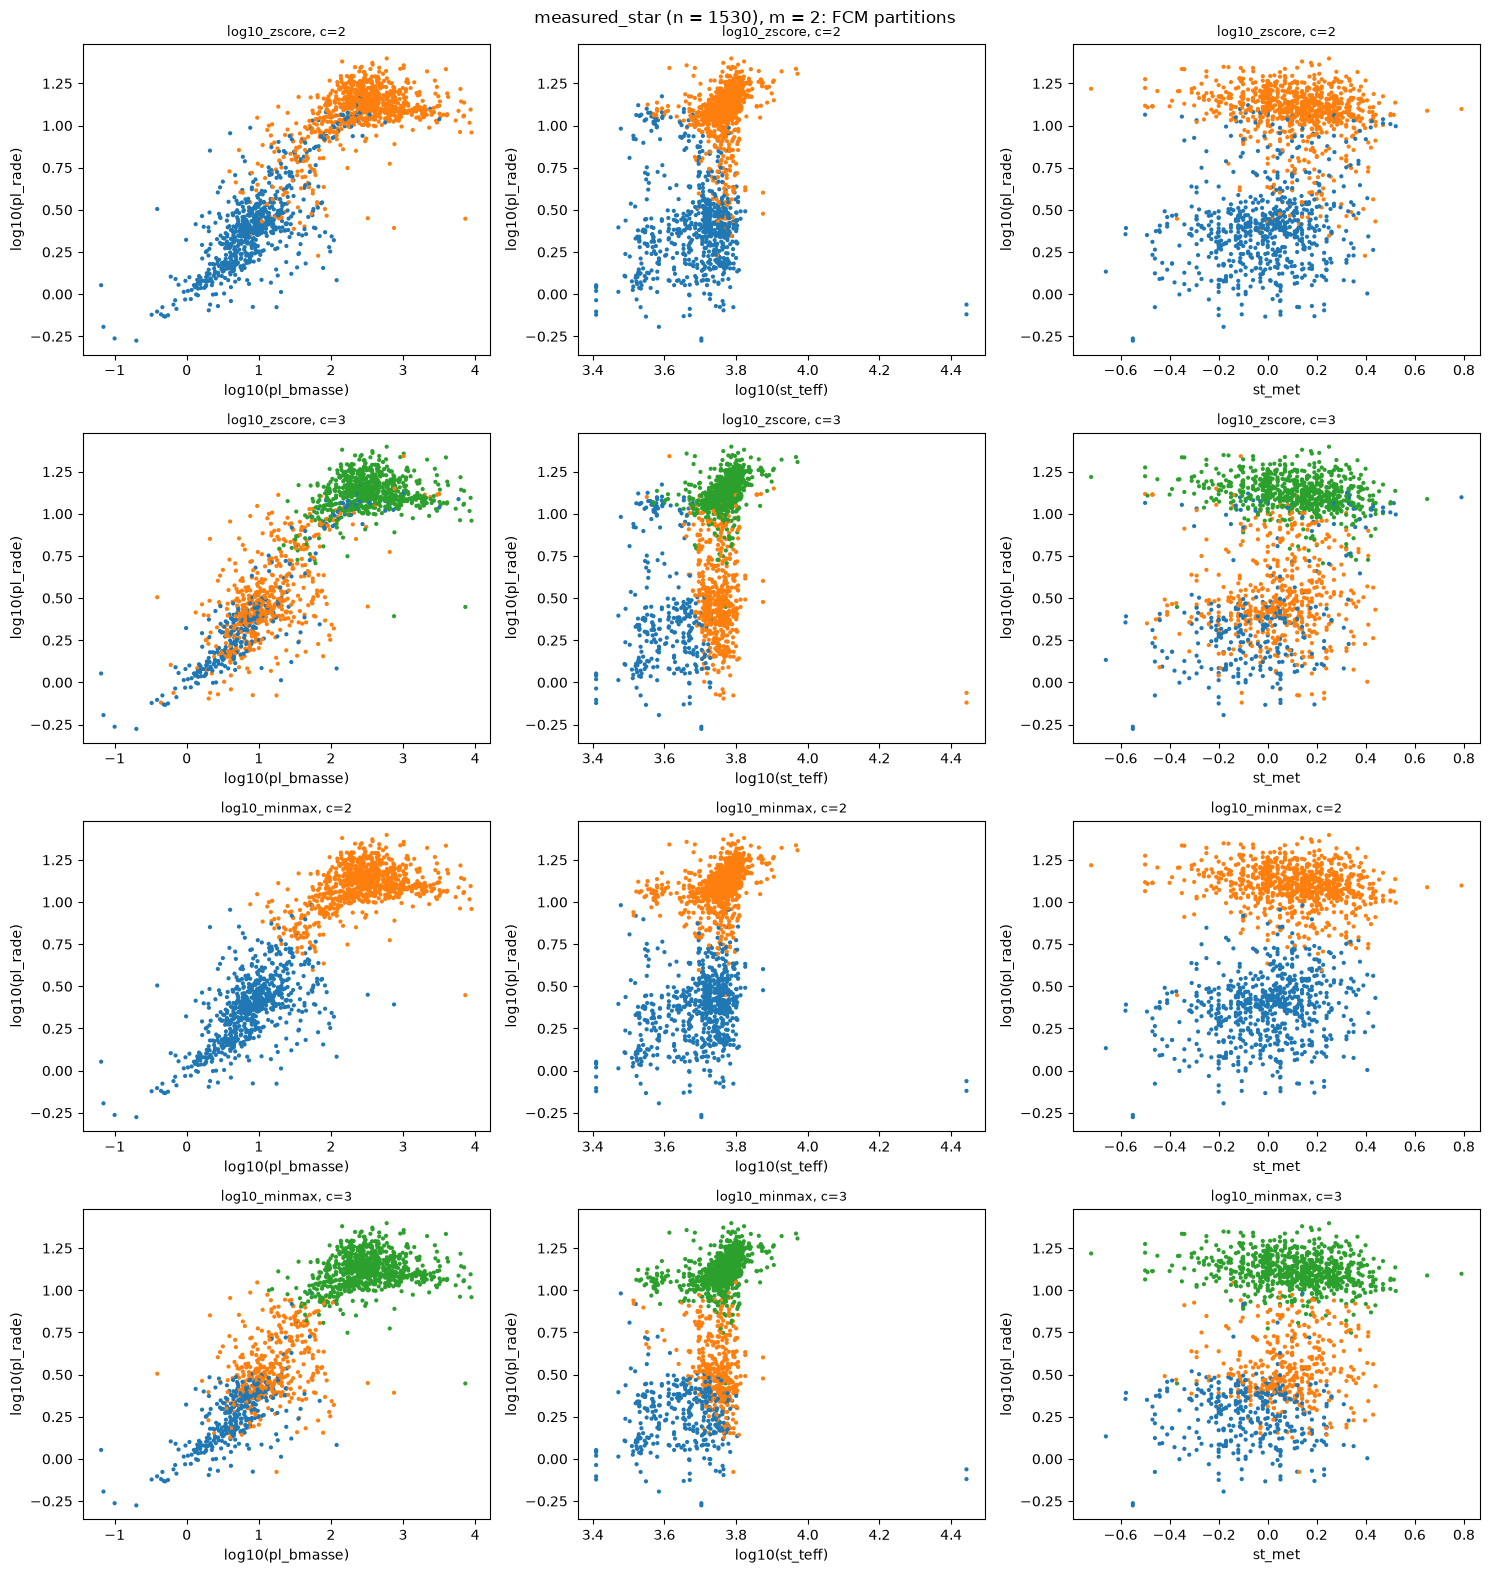

In [70]:
STAR_PLANES = [("pl_bmasse", "pl_rade"), ("st_teff", "pl_rade"), ("st_met", "pl_rade")]
lxs = {c: (ts[c] if c in NOT_LOGGED else np.log10(ts[c])) for c in FEATURE_SETS["measured_star"]}
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for r, (vname, c) in enumerate([(v, c) for v in VARIANTS for c in PART_C]):
    labels = star_parts[(vname, 2.0, c)]
    for j, (xc, yc) in enumerate(STAR_PLANES):
        ax = axes[r, j]
        ax.scatter(lxs[xc], lxs[yc], s=4, c=COLORS[labels])
        ax.set_xlabel(xc if xc in NOT_LOGGED else f"log10({xc})")
        ax.set_ylabel(f"log10({yc})")
        ax.set_title(f"{vname}, c={c}", fontsize=9)
fig.suptitle(f"measured_star (n = {len(ts)}), m = 2: FCM partitions")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_measured_star_partitions_m2.png", dpi=200)
plt.show()

## Step 12: Stability under resampling

Is the c = 2 partition of `measured` a property of the data or of this particular sample? `N_SUB` = 10 random
subsamples of 70 % of the planets (seeds `SEED + r`). On each subsample the whole pipeline is refitted (log10 scaling
fitted on the subsample only, FCM with 10 starts), and its partition is compared (ARI) with the full-data partition
restricted to the same planets. c = 3 is run the same way for contrast. m = 2, both variants.

In [71]:
N_SUB, FRAC = 10, 0.7
L_meas = log_view(t, FEATURE_SETS["measured"]).to_numpy(dtype=float)
stab_rows = []
for r in range(N_SUB):
    rng = np.random.default_rng(SEED + r)
    idx = np.sort(rng.choice(len(t), size=int(FRAC * len(t)), replace=False))
    for vname, f in VARIANTS.items():
        A_sub = f(L_meas[idx])
        for c in PART_C:
            best, info = fcm.fcm_multistart(A_sub, c, m=M_MAIN, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
            Vl = best.V * (L_meas[idx].std(axis=0) if vname == "log10_zscore" else np.ptp(L_meas[idx], axis=0)) \
                 + (L_meas[idx].mean(axis=0) if vname == "log10_zscore" else L_meas[idx].min(axis=0))
            order = np.argsort(Vl[:, FEATURE_SETS["measured"].index("pl_rade")])
            proto = 10 ** Vl[order]
            stab_rows.append({
                "subsample": r, "variant": vname, "c": c,
                "ARI vs full data": adjusted_rand_score(parts[("measured", vname, M_MAIN, c)]["labels"][idx], best.labels),
                "sizes": np.bincount(best.U[order].argmax(axis=0), minlength=c).tolist(),
                **{f"proto{k}_{col}": proto[k, j] for k in range(c) for j, col in enumerate(FEATURE_SETS["measured"])},
            })
stab = pd.DataFrame(stab_rows)
stab.to_csv(OUT_DIR / "pscomppars_measured_stability.csv", index=False)
print(stab.groupby(["variant", "c"])["ARI vs full data"].describe()[["mean", "min", "max"]].round(3))

                 mean    min    max
variant      c                     
log10_minmax 2  0.995  0.982  1.000
             3  0.962  0.911  0.988
log10_zscore 2  0.994  0.982  1.000
             3  0.920  0.862  0.974


In [72]:
# Spread of the prototypes (physical units) over the subsamples, c = 2
cols = [c for c in stab.columns if c.startswith("proto")]
stab[stab["c"] == 2].groupby("variant")[[c for c in cols if c[5] in "01"]].agg(["min", "max"]).round(2).T

variant               log10_minmax  log10_zscore
proto0_pl_orbper min          8.01          9.20
                 max          8.52          9.85
proto0_pl_rade   min          2.27          2.41
                 max          2.36          2.49
proto0_pl_bmasse min          7.17          7.97
                 max          7.81          8.49
proto1_pl_orbper min          5.42          4.53
                 max          5.66          4.81
proto1_pl_rade   min         12.65         12.59
                 max         12.90         12.82
proto1_pl_bmasse min        283.83        280.30
                 max        318.87        310.99

## Step 13: Inside the small-planet cluster

Does FCM find sub-groups among the small planets? The small planets are the planets assigned to cluster 0 (smallest
prototype radius) of the main run (`measured`, log10_zscore, m = 2, c = 2). Two feature sets:

- **small_PRM**: period, radius, mass (as before)
- **small_R**: radius only (one-dimensional FCM)

Scaling is refitted on the small planets. c = 2 ... 6, m in {1.5, 2}, both variants, 10 starts.
For c = 2, the radius where the hard assignment switches is reported and shown on the radius histogram.

In [73]:
main_labels = parts[("measured", "log10_zscore", 2.0, 2)]["labels"]
small = tables["measured"].loc[main_labels == 0].reset_index(drop=True)
FEATURE_SETS["small_PRM"] = ["pl_orbper", "pl_rade", "pl_bmasse"]
FEATURE_SETS["small_R"] = ["pl_rade"]
tables["small_PRM"] = tables["small_R"] = small
print("small planets:", len(small), " radius range:", small["pl_rade"].min().round(2), "-", small["pl_rade"].max().round(2))

def run_grid(tname, c_range=range(2, 7), m_list=(1.5, 2.0)):
    """Scaling (refitted on this table) + FCM grid. Returns (rows DataFrame, runs dict, data dict)."""
    L = log_view(tables[tname], FEATURE_SETS[tname]).to_numpy(dtype=float)
    rows, runs, dat = [], {}, {}
    for vname, f in VARIANTS.items():
        A = f(L)
        dat[vname] = A
        for m in m_list:
            for c in c_range:
                best, info = fcm.fcm_multistart(A, c, m=m, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
                runs[(vname, m, c)] = best
                rows.append({"table": tname, "variant": vname, "m": m, "c": c, **fcm.validity_indices(A, best, m),
                             **fcm.prototype_diagnostics(A, best), "n_at_best": info["n_at_best"]})
    return pd.DataFrame(rows), runs, dat

def preferred_c(g):
    out = []
    for (tname, vname, m), gg in g.groupby(["table", "variant", "m"], sort=False):
        valid = gg[gg["n_distinct"] == gg["c"]].set_index("c")
        out.append({"table": tname, "variant": vname, "m": m,
                    **{idx: (valid[idx].idxmax() if d == "max" else valid[idx].idxmin()) for idx, d in INDICES.items()}})
    return pd.DataFrame(out)

extra_runs, extra_data, extra_grid = {}, {}, []
for tname in ("small_PRM", "small_R"):
    g, runs, dat = run_grid(tname)
    extra_grid.append(g)
    extra_runs[tname], extra_data[tname] = runs, dat
extra_grid = pd.concat(extra_grid)
extra_grid.to_csv(OUT_DIR / "pscomppars_small_planets_grid.csv", index=False)
preferred_c(extra_grid)

small planets: 721  radius range: 0.53 - 12.95


,table,variant,m,PC,NPC,PE,NPE,XB,FS
0,small_PRM,log10_zscore,1.5,2,2,2,6,2,6
1,small_PRM,log10_zscore,2.0,2,2,2,2,2,6
2,small_PRM,log10_minmax,1.5,2,3,2,3,3,6
3,small_PRM,log10_minmax,2.0,2,3,2,3,3,5
4,small_R,log10_zscore,1.5,3,3,3,6,3,6
5,small_R,log10_zscore,2.0,3,3,2,6,3,6
6,small_R,log10_minmax,1.5,3,3,3,6,3,6
7,small_R,log10_minmax,2.0,3,3,2,6,3,6


In [74]:
# NPC and XB vs c (to see how clear the preference is)
extra_grid.pivot_table(index=["table", "variant", "m"], columns="c", values=["NPC", "XB"]).round(3)

NPC                                 XB         \
c                               2      3      4      5      6      2      3   
table     variant      m                                                      
small_PRM log10_minmax 1.5  0.741  0.763  0.695  0.671  0.667  0.231  0.202   
                       2.0  0.461  0.475  0.394  0.359  0.323  0.232  0.206   
          log10_zscore 1.5  0.687  0.637  0.583  0.598  0.599  0.324  0.435   
                       2.0  0.386  0.333  0.277  0.256  0.247  0.354  0.535   
small_R   log10_minmax 1.5  0.781  0.875  0.856  0.857  0.869  0.147  0.088   
                       2.0  0.580  0.695  0.655  0.663  0.671  0.137  0.080   
          log10_zscore 1.5  0.781  0.875  0.856  0.857  0.869  0.147  0.088   
                       2.0  0.580  0.695  0.655  0.663  0.671  0.137  0.080   

                                                 
c                               4      5      6  
table     variant      m                         
small_PRM log10_minmax 1.5  0.401  0.490  0.357  
                       2.0  0.492  0.596  0.603  
          log10_zscore 1.5  0.581  0.398  0.459  
                       2.0  0.762  0.755  0.585  
small_R   log10_minmax 1.5  0.162  0.118  0.139  
                       2.0  0.152  0.104  0.128  
          log10_zscore 1.5  0.162  0.118  0.139  
                       2.0  0.152  0.104  0.128

In [75]:
# c = 2 inside the small planets: prototypes in physical units and the radius where the assignment switches
rows = []
for tname in ("small_PRM", "small_R"):
    for vname in VARIANTS:
        for m in (1.5, 2.0):
            U, phys = ordered_partition(tname, vname, extra_runs[tname][(vname, m, 2)])
            labels = U.argmax(axis=0)
            r = small["pl_rade"].to_numpy()
            rows.append({"table": tname, "variant": vname, "m": m,
                         "sizes": np.bincount(labels, minlength=2).tolist(),
                         "proto radius": phys["pl_rade"].round(3).tolist(),
                         "max radius in cluster 0": r[labels == 0].max().round(3),
                         "min radius in cluster 1": r[labels == 1].min().round(3),
                         "radius overlap (planets in the other cluster's range)":
                             int(((labels == 0) & (r > r[labels == 1].min())).sum() + ((labels == 1) & (r < r[labels == 0].max())).sum()),
                         **({"proto period": phys["pl_orbper"].round(2).tolist(),
                             "proto mass": phys["pl_bmasse"].round(2).tolist()} if "pl_orbper" in phys else {})})
small_c2 = pd.DataFrame(rows)
small_c2.to_csv(OUT_DIR / "pscomppars_small_planets_c2.csv", index=False)
small_c2

,table,variant,m,sizes,proto radius,max radius in cluster 0,min radius in cluster 1,radius overlap (planets in the other cluster's range),proto period,proto mass
0,small_PRM,log10_zscore,1.5,"[313, 408]","[1.629, 3.349]",3.20,1.21,480,"[4.13, 16.64]","[3.74, 14.24]"
1,small_PRM,log10_zscore,2.0,"[319, 402]","[1.704, 3.298]",3.20,1.21,480,"[4.46, 16.34]","[4.11, 13.77]"
2,small_PRM,log10_minmax,1.5,"[302, 419]","[1.574, 3.418]",3.20,1.69,376,"[4.43, 15.23]","[3.79, 13.85]"
3,small_PRM,log10_minmax,2.0,"[319, 402]","[1.628, 3.42]",3.20,1.75,361,"[4.63, 14.9]","[4.04, 13.71]"
4,small_R,log10_zscore,1.5,"[337, 384]","[1.61, 3.575]",2.39,2.40,0,NaN,NaN
5,small_R,log10_zscore,2.0,"[337, 384]","[1.616, 3.562]",2.39,2.40,0,NaN,NaN
6,small_R,log10_minmax,1.5,"[337, 384]","[1.61, 3.575]",2.39,2.40,0,NaN,NaN
7,small_R,log10_minmax,2.0,"[337, 384]","[1.616, 3.562]",2.39,2.40,0,NaN,NaN


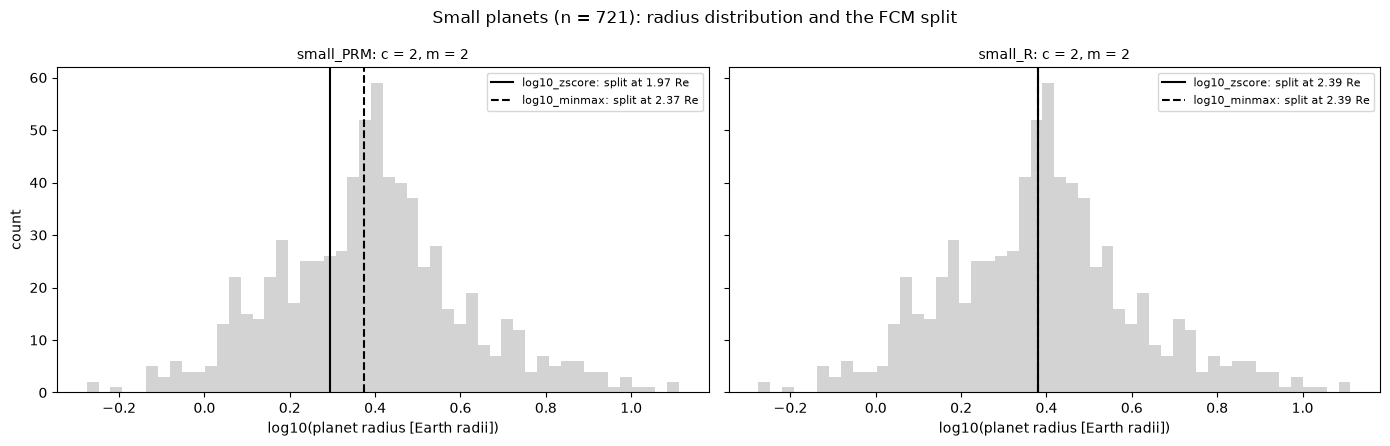

In [76]:
# Radius histogram of the small planets, with the c = 2 split of each run (m = 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
logr = np.log10(small["pl_rade"])
bins = np.histogram_bin_edges(logr, bins=50)
for ax, tname in zip(axes, ("small_PRM", "small_R")):
    ax.hist(logr, bins=bins, color="lightgrey")
    for vname, ls in zip(VARIANTS, ["-", "--"]):
        U, _ = ordered_partition(tname, vname, extra_runs[tname][(vname, 2.0, 2)])
        labels = U.argmax(axis=0)
        split = (small["pl_rade"][labels == 0].max() * small["pl_rade"][labels == 1].min()) ** 0.5
        ax.axvline(np.log10(split), color="black", linestyle=ls, label=f"{vname}: split at {split:.2f} Re")
    ax.set_xlabel("log10(planet radius [Earth radii])")
    ax.set_title(f"{tname}: c = 2, m = 2", fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel("count")
fig.suptitle(f"Small planets (n = {len(small)}): radius distribution and the FCM split")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_small_planets_radius_split.png", dpi=200)
plt.show()

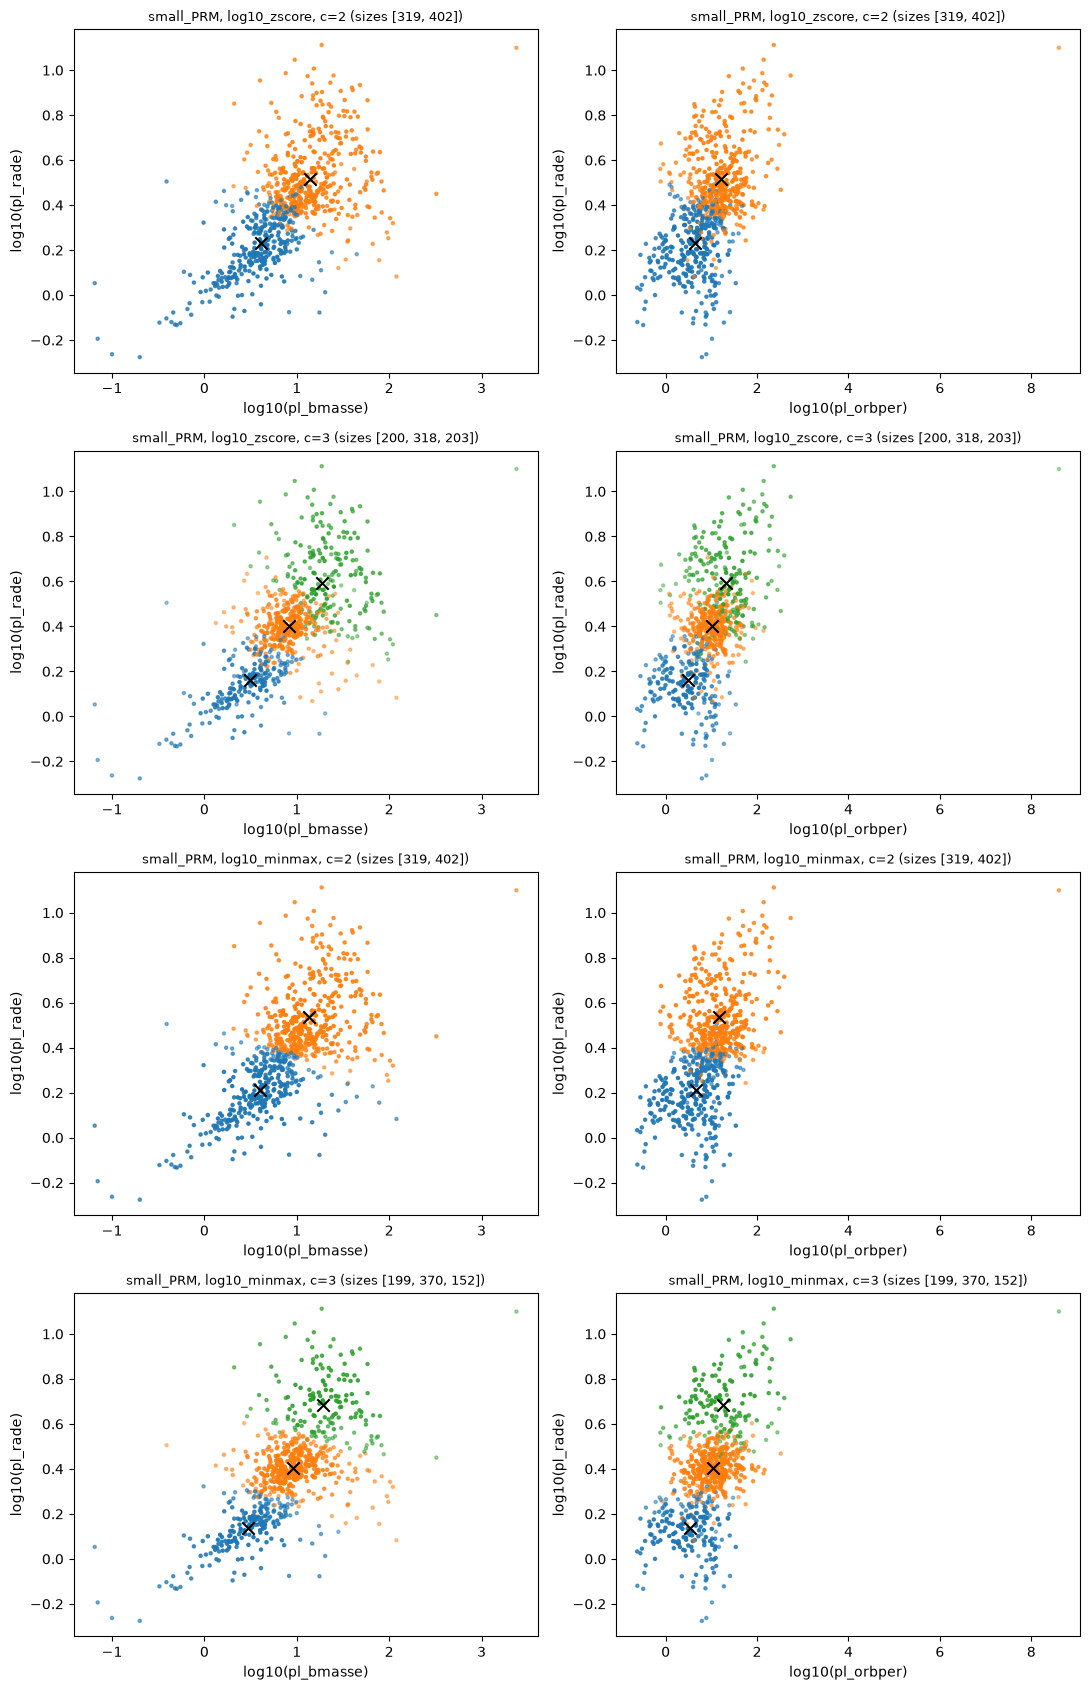

In [77]:
# small_PRM, m = 2: partitions c = 2 and 3 in the mass-radius and period-radius planes
fig, axes = plt.subplots(4, 2, figsize=(11, 17))
for r, (vname, c) in enumerate([(v, c) for v in VARIANTS for c in (2, 3)]):
    U, phys = ordered_partition("small_PRM", vname, extra_runs["small_PRM"][(vname, 2.0, c)])
    labels, maxu = U.argmax(axis=0), U.max(axis=0)
    for j, (xc, yc) in enumerate(PLANES):
        ax = axes[r, j]
        rgba = [(*mcolors.to_rgb(col), a) for col, a in zip(COLORS[labels], maxu)]
        ax.scatter(np.log10(small[xc]), np.log10(small[yc]), s=5, c=rgba)
        ax.scatter(np.log10(phys[xc]), np.log10(phys[yc]), marker="x", s=80, color="black")
        ax.set_xlabel(f"log10({xc})")
        ax.set_ylabel(f"log10({yc})")
        ax.set_title(f"small_PRM, {vname}, c={c} (sizes {np.bincount(labels).tolist()})", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_small_planets_partitions_m2.png", dpi=200)
plt.show()

## Step 14: Adding the insolation

Insolation S (flux received by the planet, in Earth units) depends on the star's luminosity and the orbit; it is not
derived from the mass–radius relation. Some values are calculated by the archive (`CALCULATED_VALUE`), the others
come from references; Step 2a showed `pl_insol` consistent with L / a² (median ratio 1.00).

Table **measured_insol**: the `measured` planets that also have a positive insolation with limit flag 0.
Feature set: radius, mass, insolation (the period is replaced by the insolation; both describe the orbit, and
insolation also contains the star). c = 2 ... 6, m in {1.5, 2}, both variants, 10 starts.

In [78]:
ins_ok = df["pl_insol"].gt(0) & df["pl_insollim"].eq(0)
mi_mask = measured_mask & ins_ok
FEATURE_SETS["measured_insol"] = ["pl_rade", "pl_bmasse", "pl_insol"]
tables["measured_insol"] = df.loc[mi_mask, INFO_COLS + ["pl_orbper", "pl_rade", "pl_bmasse", "pl_insol"]].reset_index(drop=True)
ti = tables["measured_insol"]
print("measured_insol:", len(ti), "of", int(measured_mask.sum()), "measured planets")
print("insolation from the archive's calculation:", int(ref_id("pl_insol")[mi_mask].eq("CALCULATED_VALUE").sum()))
print("planets of measured without usable insolation, by method:")
print(df.loc[measured_mask & ~ins_ok, "discoverymethod"].value_counts(), "\n")
print("Spearman correlations (measured_insol):")
print(ti[["pl_orbper", "pl_rade", "pl_bmasse", "pl_insol"]].corr(method="spearman").round(3))

g, runs, dat = run_grid("measured_insol")
extra_grid_i = g
extra_runs["measured_insol"], extra_data["measured_insol"] = runs, dat
extra_grid_i.to_csv(OUT_DIR / "pscomppars_measured_insol_grid.csv", index=False)
preferred_c(extra_grid_i)

measured_insol: 1555 of 1564 measured planets
insolation from the archive's calculation: 93
planets of measured without usable insolation, by method:
discoverymethod
Transit    6
Imaging    3
Name: count, dtype: int64 

Spearman correlations (measured_insol):
           pl_orbper  pl_rade  pl_bmasse  pl_insol
pl_orbper      1.000   -0.255     -0.206    -0.708
pl_rade       -0.255    1.000      0.843     0.503
pl_bmasse     -0.206    0.843      1.000     0.401
pl_insol      -0.708    0.503      0.401     1.000


,table,variant,m,PC,NPC,PE,NPE,XB,FS
0,measured_insol,log10_zscore,1.5,2,2,2,2,2,6
1,measured_insol,log10_zscore,2.0,2,2,2,2,2,4
2,measured_insol,log10_minmax,1.5,2,2,2,2,2,6
3,measured_insol,log10_minmax,2.0,2,2,2,2,2,2


In [79]:
extra_grid_i.pivot_table(index=["variant", "m"], columns="c", values=["NPC", "XB"]).round(3)

NPC                                 XB                \
c                     2      3      4      5      6      2      3      4   
variant      m                                                             
log10_minmax 1.5  0.908  0.823  0.757  0.753  0.722  0.083  0.223  0.318   
             2.0  0.735  0.566  0.485  0.441  0.388  0.076  0.240  0.371   
log10_zscore 1.5  0.848  0.802  0.757  0.737  0.713  0.150  0.205  0.297   
             2.0  0.632  0.517  0.474  0.423  0.397  0.141  0.206  0.307   

                                
c                     5      6  
variant      m                  
log10_minmax 1.5  0.293  0.435  
             2.0  0.461  0.536  
log10_zscore 1.5  0.315  0.306  
             2.0  0.443  0.439

In [80]:
# Prototypes (physical units) for c = 2 ... 4, m = 2, and agreement of c = 2 with the main measured partition
pos_in_meas = pd.Series(np.arange(len(t)), index=t["pl_name"]).loc[ti["pl_name"]].to_numpy()
rows = []
for vname in VARIANTS:
    for c in (2, 3, 4):
        U, phys = ordered_partition("measured_insol", vname, extra_runs["measured_insol"][(vname, 2.0, c)])
        labels = U.argmax(axis=0)
        ari = adjusted_rand_score(parts[("measured", vname, 2.0, 2)]["labels"][pos_in_meas], labels)
        for k in range(c):
            rows.append({"variant": vname, "c": c, "cluster": k, "size": int((labels == k).sum()),
                         "mean max u": round(float(U.max(axis=0)[labels == k].mean()), 3),
                         "ARI vs measured c=2": round(ari, 3), **phys.iloc[k].round(3).to_dict()})
insol_protos = pd.DataFrame(rows)
insol_protos.to_csv(OUT_DIR / "pscomppars_measured_insol_prototypes.csv", index=False)
insol_protos

,variant,c,cluster,size,mean max u,ARI vs measured c=2,pl_rade,pl_bmasse,pl_insol
0,log10_zscore,2,0,732,0.865,0.909,2.533,8.720,56.155
1,log10_zscore,2,1,823,0.889,0.909,12.696,294.311,455.975
2,log10_zscore,3,0,628,0.773,0.646,2.226,6.754,72.173
3,log10_zscore,3,1,298,0.658,0.646,7.808,93.792,31.896
4,log10_zscore,3,2,629,0.844,0.646,13.692,331.431,816.736
5,log10_zscore,4,0,346,0.676,0.504,2.101,6.978,229.837
6,log10_zscore,4,1,349,0.683,0.504,2.673,8.608,19.274
7,log10_zscore,4,2,299,0.638,0.504,10.161,191.102,53.292
8,log10_zscore,4,3,561,0.812,0.504,14.182,343.722,958.046
9,log10_minmax,2,0,694,0.909,0.977,2.333,7.680,68.172


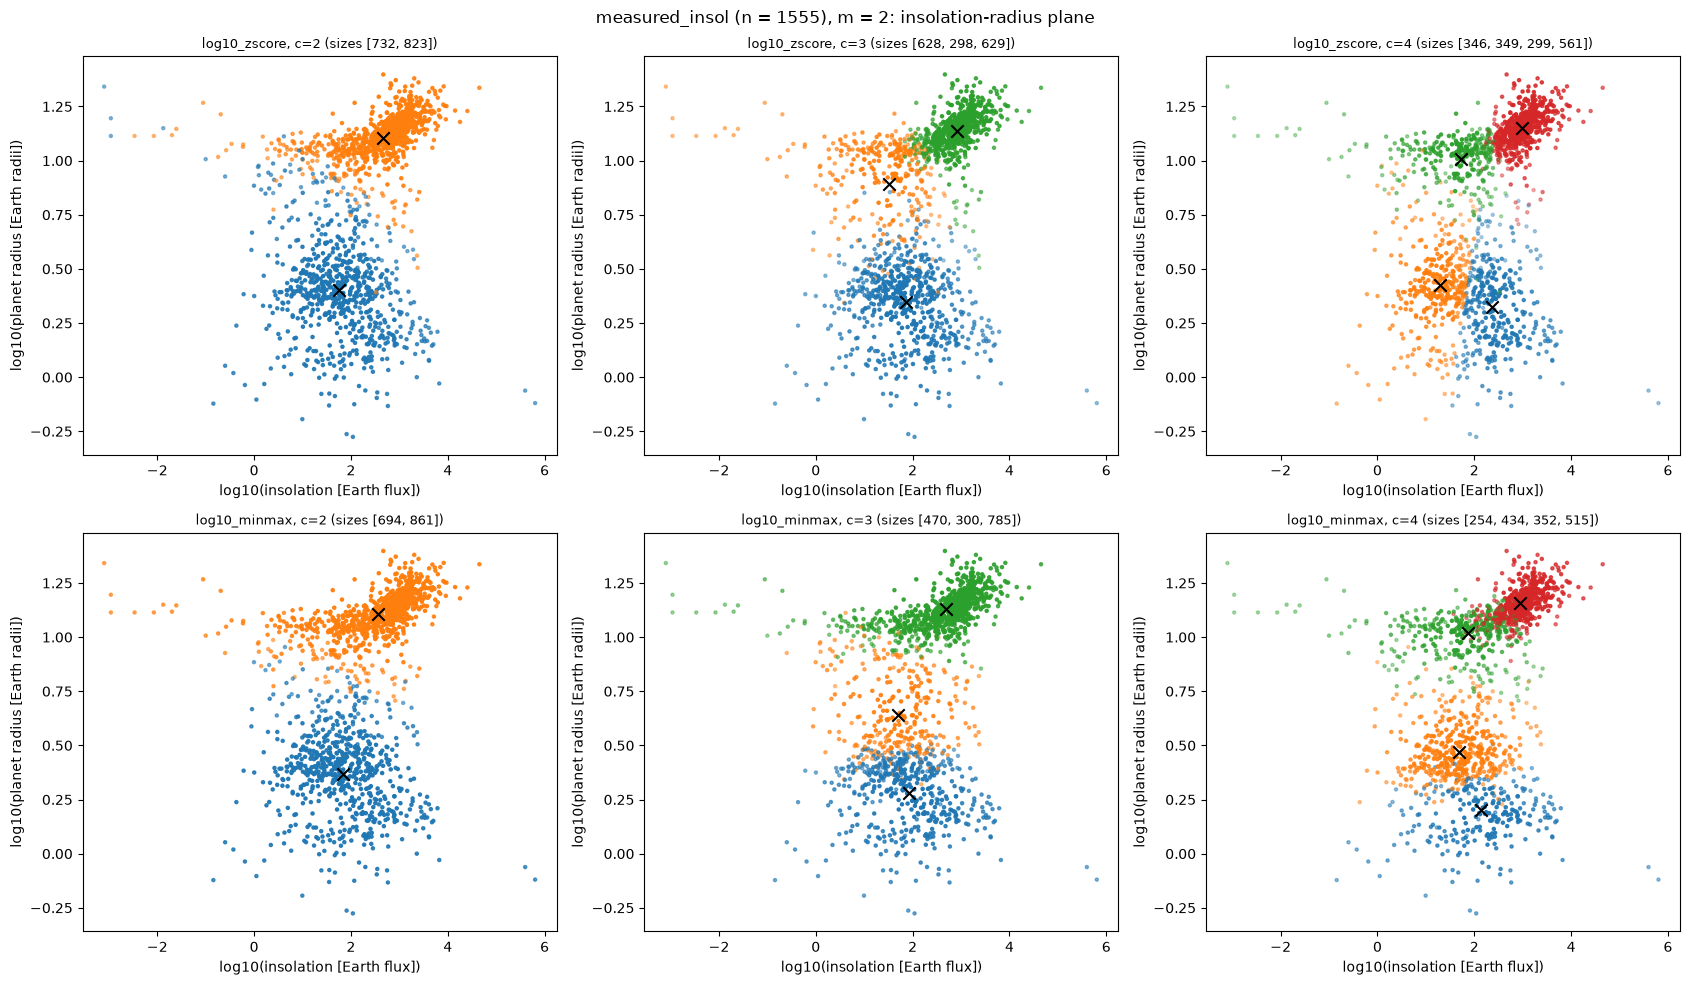

In [81]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for r, vname in enumerate(VARIANTS):
    for j, c in enumerate((2, 3, 4)):
        U, phys = ordered_partition("measured_insol", vname, extra_runs["measured_insol"][(vname, 2.0, c)])
        labels, maxu = U.argmax(axis=0), U.max(axis=0)
        cols4 = np.array(["tab:blue", "tab:orange", "tab:green", "tab:red"])
        rgba = [(*mcolors.to_rgb(col), a) for col, a in zip(cols4[labels], maxu)]
        ax = axes[r, j]
        ax.scatter(np.log10(ti["pl_insol"]), np.log10(ti["pl_rade"]), s=5, c=rgba)
        ax.scatter(np.log10(phys["pl_insol"]), np.log10(phys["pl_rade"]), marker="x", s=80, color="black")
        ax.set_xlabel("log10(insolation [Earth flux])")
        ax.set_ylabel("log10(planet radius [Earth radii])")
        ax.set_title(f"{vname}, c={c} (sizes {np.bincount(labels).tolist()})", fontsize=9)
fig.suptitle(f"measured_insol (n = {len(ti)}), m = 2: insolation-radius plane")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_measured_insol_partitions_m2.png", dpi=200)
plt.show()

## Step 15: Is the split of the giants by insolation stable?

In Step 14 (c = 4) the giant planets were split into a lower-insolation and a higher-insolation group with both
scalings, although the validity indices preferred c = 2. Two checks:

- **15a** FCM on the giants only (radius, mass, insolation; scaling refitted on them), c = 2 ... 5: which c do the
  indices prefer, and where does the c = 2 split fall on the insolation axis?
- **15b** the c = 4 run of Step 14 on 10 random subsamples of 70 % (scaling and FCM refitted each time): agreement
  with the full-data partition, overall and on the giants only (their split into the two giant clusters).

The giants are the `measured_insol` planets in the giant cluster of the main run (`measured`, log10_zscore, m = 2, c = 2).

In [82]:
giant_main = parts[("measured", "log10_zscore", 2.0, 2)]["labels"][pos_in_meas] == 1
giants = ti.loc[giant_main].reset_index(drop=True)
FEATURE_SETS["giants_RMS"] = ["pl_rade", "pl_bmasse", "pl_insol"]
tables["giants_RMS"] = giants
print("giants with insolation:", len(giants))

g, runs, dat = run_grid("giants_RMS", c_range=range(2, 6))
extra_runs["giants_RMS"], extra_data["giants_RMS"] = runs, dat
g.to_csv(OUT_DIR / "pscomppars_giants_grid.csv", index=False)
print(preferred_c(g), "\n")
g.pivot_table(index=["variant", "m"], columns="c", values=["NPC", "XB"]).round(3)

giants with insolation: 837
        table       variant    m  PC  NPC  PE  NPE  XB  FS
0  giants_RMS  log10_zscore  1.5   2    3   2    5   3   5
1  giants_RMS  log10_zscore  2.0   2    2   2    5   5   5
2  giants_RMS  log10_minmax  1.5   2    3   2    5   3   5
3  giants_RMS  log10_minmax  2.0   2    3   2    3   3   5 



NPC                          XB                     
c                     2      3      4      5      2      3      4      5
variant      m                                                          
log10_minmax 1.5  0.647  0.698  0.686  0.674  0.389  0.262  0.323  0.352
             2.0  0.354  0.383  0.332  0.331  0.442  0.319  0.490  0.350
log10_zscore 1.5  0.676  0.691  0.667  0.673  0.374  0.265  0.431  0.271
             2.0  0.386  0.350  0.319  0.322  0.418  0.399  0.431  0.311

In [83]:
# c = 2 on the giants: prototypes and where the assignment switches along insolation (clusters ordered by radius)
rows = []
S = giants["pl_insol"].to_numpy()
for vname in VARIANTS:
    for m in (1.5, 2.0):
        U, phys = ordered_partition("giants_RMS", vname, extra_runs["giants_RMS"][(vname, m, 2)])
        labels = U.argmax(axis=0)
        rows.append({"variant": vname, "m": m, "sizes": np.bincount(labels, minlength=2).tolist(),
                     "proto radius": phys["pl_rade"].round(2).tolist(), "proto mass": phys["pl_bmasse"].round(1).tolist(),
                     "proto insolation": phys["pl_insol"].round(1).tolist(),
                     "median S cluster 0": round(float(np.median(S[labels == 0])), 1),
                     "median S cluster 1": round(float(np.median(S[labels == 1])), 1),
                     "mean max u": round(float(U.max(axis=0).mean()), 3)})
giants_c2 = pd.DataFrame(rows)
giants_c2.to_csv(OUT_DIR / "pscomppars_giants_c2.csv", index=False)
print("ARI z-score vs min-max (m = 2):", round(adjusted_rand_score(
    extra_runs["giants_RMS"][("log10_zscore", 2.0, 2)].labels, extra_runs["giants_RMS"][("log10_minmax", 2.0, 2)].labels), 3))
giants_c2

ARI z-score vs min-max (m = 2): 0.429


,variant,m,sizes,proto radius,proto mass,proto insolation,median S cluster 0,median S cluster 1,mean max u
0,log10_zscore,1.5,"[324, 513]","[10.27, 14.63]","[171.0, 425.2]","[70.9, 847.9]",95.1,991.2,0.889
1,log10_zscore,2.0,"[339, 498]","[10.56, 14.6]","[187.0, 407.6]","[83.4, 855.4]",97.9,1002.3,0.782
2,log10_minmax,1.5,"[333, 504]","[10.82, 14.26]","[134.7, 546.8]","[129.0, 641.4]",195.0,948.9,0.877
3,log10_minmax,2.0,"[353, 484]","[11.13, 14.15]","[151.1, 536.8]","[145.2, 664.0]",210.6,986.7,0.767


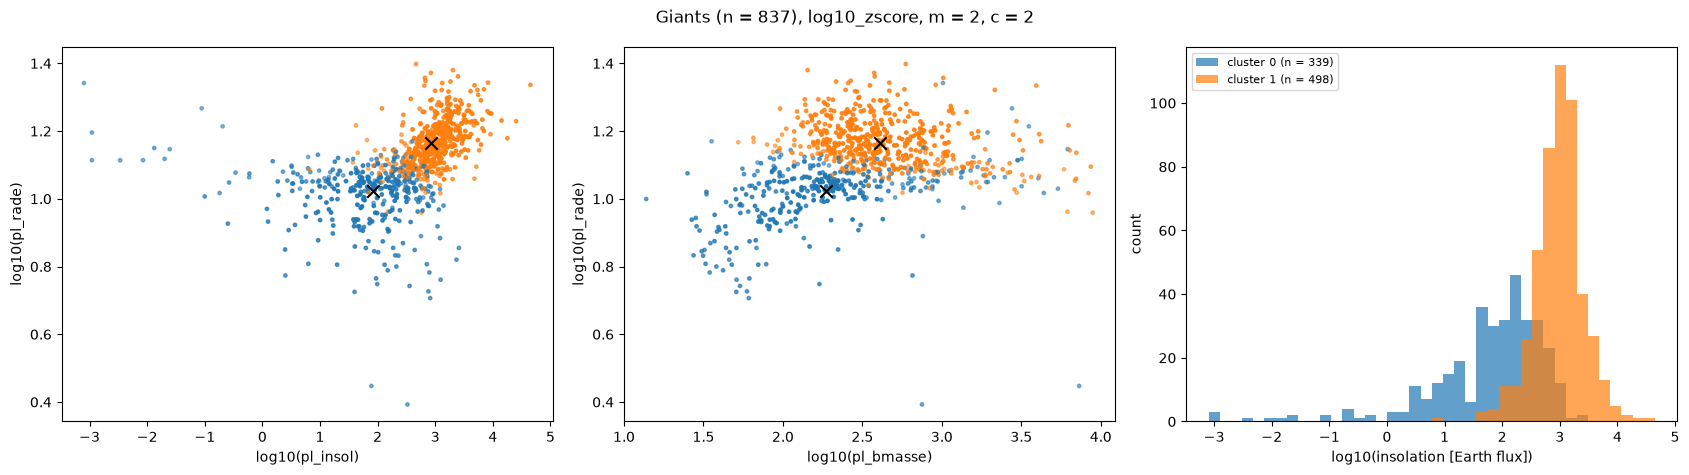

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
U, phys = ordered_partition("giants_RMS", "log10_zscore", extra_runs["giants_RMS"][("log10_zscore", 2.0, 2)])
labels, maxu = U.argmax(axis=0), U.max(axis=0)
rgba = [(*mcolors.to_rgb(col), a) for col, a in zip(COLORS[labels], maxu)]
for ax, (xc, yc) in zip(axes[:2], [("pl_insol", "pl_rade"), ("pl_bmasse", "pl_rade")]):
    ax.scatter(np.log10(giants[xc]), np.log10(giants[yc]), s=6, c=rgba)
    ax.scatter(np.log10(phys[xc]), np.log10(phys[yc]), marker="x", s=80, color="black")
    ax.set_xlabel(f"log10({xc})")
    ax.set_ylabel(f"log10({yc})")
ax = axes[2]
bins = np.histogram_bin_edges(np.log10(S), bins=40)
for k in range(2):
    ax.hist(np.log10(S[labels == k]), bins=bins, alpha=0.7, color=COLORS[k], label=f"cluster {k} (n = {(labels == k).sum()})")
ax.set_xlabel("log10(insolation [Earth flux])")
ax.set_ylabel("count")
ax.legend(fontsize=8)
fig.suptitle(f"Giants (n = {len(giants)}), log10_zscore, m = 2, c = 2")
fig.tight_layout()
fig.savefig(FIG_DIR / "pscomppars_giants_c2.png", dpi=200)
plt.show()

### 15b. The c = 4 partition of `measured_insol` on subsamples

In [85]:
L_ins = log_view(ti, FEATURE_SETS["measured_insol"]).to_numpy(dtype=float)
r_col = FEATURE_SETS["measured_insol"].index("pl_rade")
full4 = {v: ordered_partition("measured_insol", v, extra_runs["measured_insol"][(v, 2.0, 4)])[0].argmax(axis=0) for v in VARIANTS}
stab4 = []
for r in range(N_SUB):
    rng = np.random.default_rng(SEED + r)
    idx = np.sort(rng.choice(len(ti), size=int(FRAC * len(ti)), replace=False))
    for vname, f in VARIANTS.items():
        Ls = L_ins[idx]
        best, _ = fcm.fcm_multistart(f(Ls), 4, m=2.0, n_init=N_INIT, seed=SEED, eps=FCM_EPS, max_iter=FCM_MAX_ITER)
        if vname == "log10_zscore":
            Vl = best.V * Ls.std(axis=0) + Ls.mean(axis=0)
        else:
            Vl = best.V * np.ptp(Ls, axis=0) + Ls.min(axis=0)
        order = np.argsort(Vl[:, r_col])
        sub_labels = best.U[order].argmax(axis=0)
        full_labels = full4[vname][idx]
        on_giants = full_labels >= 2                     # planets in the two giant clusters of the full run
        stab4.append({"subsample": r, "variant": vname,
                      "ARI all planets": adjusted_rand_score(full_labels, sub_labels),
                      "ARI giants only": adjusted_rand_score(full_labels[on_giants], sub_labels[on_giants]),
                      "proto S (giant clusters)": np.round(10 ** Vl[order][2:, FEATURE_SETS["measured_insol"].index("pl_insol")], 1).tolist(),
                      "proto R (giant clusters)": np.round(10 ** Vl[order][2:, r_col], 2).tolist()})
stab4 = pd.DataFrame(stab4)
stab4.to_csv(OUT_DIR / "pscomppars_measured_insol_c4_stability.csv", index=False)
print(stab4.groupby("variant")[["ARI all planets", "ARI giants only"]].describe().loc[:, (slice(None), ["mean", "min", "max"])].round(3))
stab4

             ARI all planets               ARI giants only              
                        mean    min    max            mean    min    max
variant                                                                 
log10_minmax           0.952  0.879  0.973           0.919  0.785  0.968
log10_zscore           0.968  0.954  0.987           0.959  0.913  0.991


,subsample,variant,ARI all planets,ARI giants only,proto S (giant clusters),proto R (giant clusters)
0,0,log10_zscore,0.970320,0.959891,"[50.4, 954.1]","[10.04, 14.18]"
1,0,log10_minmax,0.953286,0.904078,"[79.3, 874.5]","[10.39, 14.34]"
2,1,log10_zscore,0.958965,0.913058,"[42.2, 899.8]","[10.2, 14.16]"
3,1,log10_minmax,0.879273,0.784786,"[53.1, 880.3]","[10.43, 14.34]"
4,2,log10_zscore,0.959494,0.952656,"[59.2, 968.9]","[10.02, 14.25]"
5,2,log10_minmax,0.950272,0.920932,"[76.0, 873.4]","[10.27, 14.39]"
6,3,log10_zscore,0.965456,0.950828,"[49.8, 906.6]","[10.36, 14.16]"
7,3,log10_minmax,0.968197,0.968165,"[74.3, 849.4]","[10.55, 14.42]"
8,4,log10_zscore,0.978143,0.987132,"[50.4, 954.8]","[10.21, 14.17]"
9,4,log10_minmax,0.969711,0.962004,"[71.0, 876.8]","[10.3, 14.39]"
